## Adherence per months

In [1]:
import pandas as pd

In [2]:
pdc=pd.read_csv(r"C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\pdc_tables\pdc_per_patient_year.csv")

In [3]:
pdc['first_lai_date'] = pd.to_datetime(pdc['first_lai_date'])
# Filter by 3 years of data before switching and after
switchers_post2016 = pdc[
    (pdc['switcher'] == True) & 
    (pdc['first_lai_date'].dt.year >= 2016)
]['idCas'].unique()

print(f"N switchers from 2016 onwards: {len(switchers_post2016)}")

pdc_2016 = pdc[
    (pdc['idCas'].isin(switchers_post2016)) & 
    (pdc['year'].between(2013, 2019))
]

print(pdc_2016['year'].value_counts().sort_index())

N switchers from 2016 onwards: 1275
year
2013     749
2014     864
2015     965
2016    1098
2017    1187
2018    1249
2019    1275
Name: count, dtype: int64


In [4]:
# PDC monthly

# Reload dispensing tables
df_23_dispensats = pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\23_antipsicotics_dispensats.csv")
df_25_mhda = pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\25_taula_farmacs_mhda_2010_2019_Final.csv")

# Filter to the 1275 patients
df_23_2016 = df_23_dispensats[df_23_dispensats['idCas'].isin(switchers_post2016)]
df_25_2016 = df_25_mhda[df_25_mhda['idCas'].isin(switchers_post2016)]

print(df_23_2016.shape)
print(df_25_2016.shape)

C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\846361285.py:4: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df_23_dispensats = pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\23_antipsicotics_dispensats.csv")


(140246, 20)
(2501, 13)


In [5]:
LAI_INTERVALS = {
    # ABILIFY MAINTENA — 28 days
    'ABILIFY MAINTENA 400MG 1 VIAL POLVO +1 VIAL DISOLV SUSPENS LIBER PROLONG': 28,
    'ABILIFY MAINTENA 300MG 1 VIAL POLVO +1 VIAL DISOLV SUSPENS LIBER PROLONG': 28,
    # TREVICTA — 84 days
    'TREVICTA 175MG 1 JERINGA PREC 0,875ML SUSP INYECT LIBERACION PROL': 84,
    'TREVICTA 350MG 1 JERINGA PRECARGADA 1,750ML SUSP INY LIBER PROLONG': 84,
    'TREVICTA 525MG 1 JERINGA PRECARGADA 2,625ML SUSP INY LIBER PROLONG': 84,
    'TREVICTA 263MG 1 JERINGA PREC 1,315ML + 2 AGUJAS SUSP INY LIBER PROL': 84,
    # XEPLION — 28 days
    'XEPLION 50MG 1 JERINGA PRECARG 0,5ML SUSPEN INYEC LIBERAC PROLONG': 28,
    'XEPLION 75MG 1 JERINGA PRECARG 0,75ML SUSPEN INYEC LIBERAC PROLONG': 28,
    'XEPLION 100MG 1 JERINGA PRECARG 1ML SUSPENS INYEC LIBERAC PROLONG': 28,
    'XEPLION 150MG 1 JERINGA PRECARG 1,5ML SUSPEN INYEC LIBERAC PROLONG': 28,
    'XEPLION 50MG 1 JER PREC + 2 AGU SUSPENS INYECT LIBERACION PROLONGADA': 28,
    'XEPLION 75MG 1 JER PREC + 2 AGU SUSPENS INYECT LIBERACION PROLONGADA': 28,
    'XEPLION 100MG 1 JER PREC + 2 AGU SUSPENS INYECT LIBERACION PROLONGADA': 28,
    'XEPLION 150MG 1 JER PREC + 2 AGU SUSPENS INYECT LIBERACION PROLONGADA': 28,
    # RISPERDAL CONSTA — 14 days
    'RISPERDAL CONSTA 25MG/VIAL 1 VIAL + 1 JER PRECARG': 14,
    'RISPERDAL CONSTA 37,5MG/VIAL 1 VIAL + 1 JER PRECAR': 14,
    'RISPERDAL CONSTA 50MG/VIAL 1 VIAL + 1 JER PRECARG': 14,
    'ZYPADHERA 210MG 1 VIAL POLVO + 1 VIAL DISOLV SUSP INY LIBERAC PROLONG': 14,
    # ZYPADHERA — 28 days,
    'ZYPADHERA 300MG 1 VIAL POLVO + 1 VIAL DISOLV SUSP INY LIBERAC PROLONG': 28,
    'ZYPADHERA 405MG 1 VIAL POLVO + 1 VIAL DISOLV SUSP INY LIBERAC PROLONG': 28,
    # HALDOL DECANOATE — 28 days
    'HALDOL DECANOATE 100 mg/ml 1 Solución inyectable': 28,
    'HALDOL DEPOT 5 AMP. 100 MG.': 28

}

IMMEDIATE_ACTION = [
    'HALOPERIDOL ESTEVE 5MG/ML 5 AMPOLLAS INYECTABLE',
    'DOGMATIL 50MG/ML 12 AMPOLLAS 2ML SOLUCION INYECTABLE',
    'DOGMATIL 50MG/ML SOLUCION INYECTABLE 12 AMPOLLAS DE 2ML',
    'DOGMATIL 50 mg/ml  5 Soluc inyect/CSE013078',
    'ZYPREXA 10MG 1 VIAL POLVO PARA SOLUCION INYECTABLE',
    'ABILIFY 7,5MG/ML 1 VIAL 1,3ML SOLUCION INYECTABLE',
]

In [6]:
def classify_product(product_name):
    if product_name in LAI_INTERVALS:
        return 'LAI'
    elif product_name in IMMEDIATE_ACTION:
        return 'IMMEDIATE_ACTION'
    else:
        return 'ORAL'

def anymes_to_date(anymes):
    anymes = str(int(anymes))
    return pd.Timestamp(year=int(anymes[:4]), month=int(anymes[4:]), day=15)

# Table 23
df_23_2016 = df_23_dispensats[df_23_dispensats['idCas'].isin(switchers_post2016)].copy()
df_23_2016['formulation_type'] = df_23_2016['DES_HIS_Producte'].apply(classify_product)
df_23_2016['dispensing_date'] = df_23_2016['Any_Mes'].apply(anymes_to_date)
df_23_2016['days_coverage'] = df_23_2016.apply(
    lambda row: LAI_INTERVALS[row['DES_HIS_Producte']] 
    if row['formulation_type'] == 'LAI' 
    else (float(str(row['Nombre_DDD_Receptes_Dispensades']).replace(',', '.')) 
          if row['formulation_type'] == 'ORAL' else 0),
    axis=1
)

# Table 25
df_25_2016 = df_25_mhda[df_25_mhda['idCas'].isin(switchers_post2016)].copy()
df_25_2016['formulation_type'] = df_25_2016['(HIS) Producte Desc'].apply(classify_product)
df_25_2016['dispensing_date'] = df_25_2016['Any_Mes'].apply(anymes_to_date)
df_25_2016['days_coverage'] = df_25_2016.apply(
    lambda row: LAI_INTERVALS[row['(HIS) Producte Desc']] 
    if row['formulation_type'] == 'LAI' else 0,
    axis=1
)

print(df_23_2016['formulation_type'].value_counts())
print(df_25_2016['formulation_type'].value_counts())

formulation_type
ORAL                84123
LAI                 56024
IMMEDIATE_ACTION       99
Name: count, dtype: int64
formulation_type
ORAL    2307
LAI      194
Name: count, dtype: int64


In [7]:
import calendar

def merge_intervals(intervals):
    if not intervals:
        return []
    sorted_intervals = sorted(intervals, key=lambda x: x[0])
    result = [sorted_intervals[0]]
    for start, end in sorted_intervals[1:]:
        prev_end = result[-1][1]
        if start <= prev_end:
            leftover = (prev_end - start).days + 1
            new_end = end + pd.Timedelta(days=leftover)
            result.append((prev_end + pd.Timedelta(days=1), new_end))
        else:
            result.append((start, end))
    return result

def days_covered_in_month(intervals, year, month, treatment_start):
    month_start = pd.Timestamp(year, month, 1)
    month_end = pd.Timestamp(year, month, calendar.monthrange(year, month)[1])
    
    # Adjust start for first month of treatment
    effective_start = max(month_start, treatment_start)
    if effective_start > month_end:
        return None, None  # patient not yet in treatment
    
    denominator = (month_end - effective_start).days + 1
    
    covered = 0
    for start, end in intervals:
        overlap_start = max(start, effective_start)
        overlap_end = min(end, month_end)
        if overlap_start <= overlap_end:
            covered += (overlap_end - overlap_start).days + 1
    
    return min(covered, denominator), denominator

def compute_monthly_pdc(patient_df_23, patient_df_25, treatment_start):
    results = []
    
    oral_intervals = []
    for _, row in patient_df_23[patient_df_23['formulation_type'] == 'ORAL'].iterrows():
        start = row['dispensing_date']
        end = start + pd.Timedelta(days=int(row['days_coverage']) - 1)
        oral_intervals.append((start, end))
    
    lai_intervals = []
    for _, row in patient_df_23[patient_df_23['formulation_type'] == 'LAI'].iterrows():
        start = row['dispensing_date']
        end = start + pd.Timedelta(days=int(row['days_coverage']) - 1)
        lai_intervals.append((start, end))
    for _, row in patient_df_25[patient_df_25['formulation_type'] == 'LAI'].iterrows():
        start = row['dispensing_date']
        end = start + pd.Timedelta(days=int(row['days_coverage']) - 1)
        lai_intervals.append((start, end))
    
    oral_merged = merge_intervals(oral_intervals)
    lai_merged = merge_intervals(lai_intervals)
    total_merged = merge_intervals(oral_intervals + lai_intervals)
    
    for year in range(treatment_start.year, 2020):
        for month in range(1, 13):
            oral_covered, denominator = days_covered_in_month(oral_merged, year, month, treatment_start)
            if oral_covered is None:
                continue
            lai_covered, _ = days_covered_in_month(lai_merged, year, month, treatment_start)
            total_covered, _ = days_covered_in_month(total_merged, year, month, treatment_start)
            
            results.append({
                'year': year,
                'month': month,
                'year_month': f"{year}-{month:02d}",
                'denominator': denominator,
                'PDC_oral': round(oral_covered / denominator, 4),
                'PDC_lai': round(lai_covered / denominator, 4),
                'PDC_total': round(total_covered / denominator, 4),
            })
    
    return pd.DataFrame(results)

In [8]:
all_results_monthly = []

for patient_id in switchers_post2016:
    p23 = df_23_2016[df_23_2016['idCas'] == patient_id]
    p25 = df_25_2016[df_25_2016['idCas'] == patient_id]
    
    dates = []
    if not p23.empty:
        dates.append(p23['dispensing_date'].min())
    if not p25.empty:
        dates.append(p25['dispensing_date'].min())
    
    if not dates:
        continue
    
    treatment_start = min(dates)
    
    pdc_df = compute_monthly_pdc(p23, p25, treatment_start)
    pdc_df['idCas'] = patient_id
    all_results_monthly.append(pdc_df)

pdc_monthly = pd.concat(all_results_monthly, ignore_index=True)
pdc_monthly = pdc_monthly.sort_values(['idCas', 'year', 'month']).reset_index(drop=True)

print(pdc_monthly.shape)
print(pdc_monthly.head(20))

(96196, 8)
    year  month year_month  denominator  PDC_oral  PDC_lai  PDC_total  \
0   2019      2    2019-02           14    1.0000   0.0000     1.0000   
1   2019      3    2019-03           31    0.1290   0.0000     0.1290   
2   2019      4    2019-04           30    0.5333   0.0000     0.5333   
3   2019      5    2019-05           31    1.0000   0.0000     1.0000   
4   2019      6    2019-06           30    1.0000   0.0000     1.0000   
5   2019      7    2019-07           31    1.0000   0.0000     1.0000   
6   2019      8    2019-08           31    1.0000   0.0000     1.0000   
7   2019      9    2019-09           30    1.0000   0.0000     1.0000   
8   2019     10    2019-10           31    1.0000   0.0000     1.0000   
9   2019     11    2019-11           30    1.0000   0.5333     1.0000   
10  2019     12    2019-12           31    1.0000   1.0000     1.0000   
11  2019      2    2019-02           14    1.0000   0.0000     1.0000   
12  2019      3    2019-03           31 

In [10]:
pdc_monthly = pdc_monthly[['idCas', 'year', 'month', 'year_month', 'denominator', 'PDC_oral', 'PDC_lai', 'PDC_total']]

In [ ]:
pdc_monthly.to_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\csv merged\pdc_monthly_switchers.csv', index=False)
print("Saved!")

In [12]:
# Add switch date to monthly data
switch_dates = pdc[pdc['switcher'] == True][['idCas', 'first_lai_date']].drop_duplicates()
switch_dates['first_lai_date'] = pd.to_datetime(switch_dates['first_lai_date'])

pdc_monthly = pdc_monthly.merge(switch_dates, on='idCas', how='left')

# Calculate months relative to switch
pdc_monthly['switch_year'] = pdc_monthly['first_lai_date'].dt.year
pdc_monthly['switch_month'] = pdc_monthly['first_lai_date'].dt.month

pdc_monthly['months_to_switch'] = (
    (pdc_monthly['year'] - pdc_monthly['switch_year']) * 12 + 
    (pdc_monthly['month'] - pdc_monthly['switch_month'])
)

# Filter to -36 to +36 months
pdc_monthly_aligned = pdc_monthly[pdc_monthly['months_to_switch'].between(-36, 36)]

print(pdc_monthly_aligned['months_to_switch'].value_counts().sort_index())

months_to_switch
-36    832
-35    842
-34    849
-33    855
-32    865
      ... 
 32    490
 33    463
 34    430
 35    397
 36    367
Name: count, Length: 73, dtype: int64


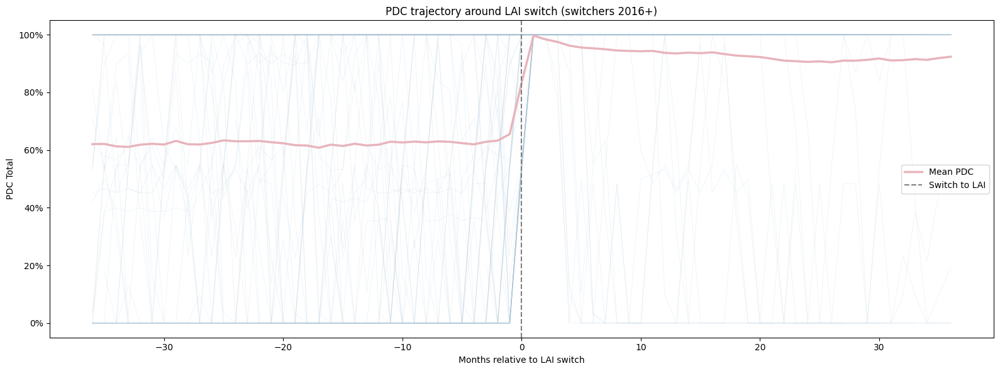

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

custom2 = ['#E8B4BC', '#B7C9A8', '#A8C5DA', '#D4B8D4', '#F0D9B5']

# Mean trajectory
mean_traj = pdc_monthly_aligned.groupby('months_to_switch')['PDC_total'].mean().reset_index()

fig, ax = plt.subplots(figsize=(16, 6))

# Spaghetti — individual trajectories (sample to avoid overplotting)
sample_ids = pdc_monthly_aligned['idCas'].drop_duplicates().sample(100, random_state=42)
for patient_id in sample_ids:
    patient_data = pdc_monthly_aligned[pdc_monthly_aligned['idCas'] == patient_id]
    ax.plot(patient_data['months_to_switch'], patient_data['PDC_total'], 
            color='#A8C5DA', alpha=0.15, linewidth=0.8)

# Mean line on top
ax.plot(mean_traj['months_to_switch'], mean_traj['PDC_total'], 
        color='#E8B4BC', linewidth=2.5, label='Mean PDC')

# Switch line
ax.axvline(x=0, color='grey', linestyle='--', label='Switch to LAI')

ax.set_xlabel('Months relative to LAI switch')
ax.set_ylabel('PDC Total')
ax.set_title('PDC trajectory around LAI switch (switchers 2016+)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend()

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\pdc_monthly_trajectory.png', dpi=150)
plt.show()

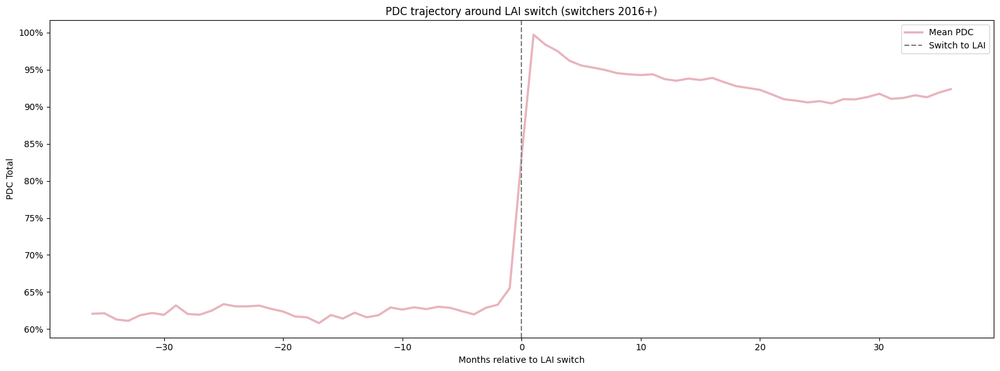

In [14]:
# Just the mean
fig, ax = plt.subplots(figsize=(16, 6))

# Mean line only
ax.plot(mean_traj['months_to_switch'], mean_traj['PDC_total'], 
        color='#E8B4BC', linewidth=2.5, label='Mean PDC')

# Switch line
ax.axvline(x=0, color='grey', linestyle='--', label='Switch to LAI')

ax.set_xlabel('Months relative to LAI switch')
ax.set_ylabel('PDC Total')
ax.set_title('PDC trajectory around LAI switch (switchers 2016+)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend()

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\pdc_monthly_mean.png', dpi=150)
plt.show()

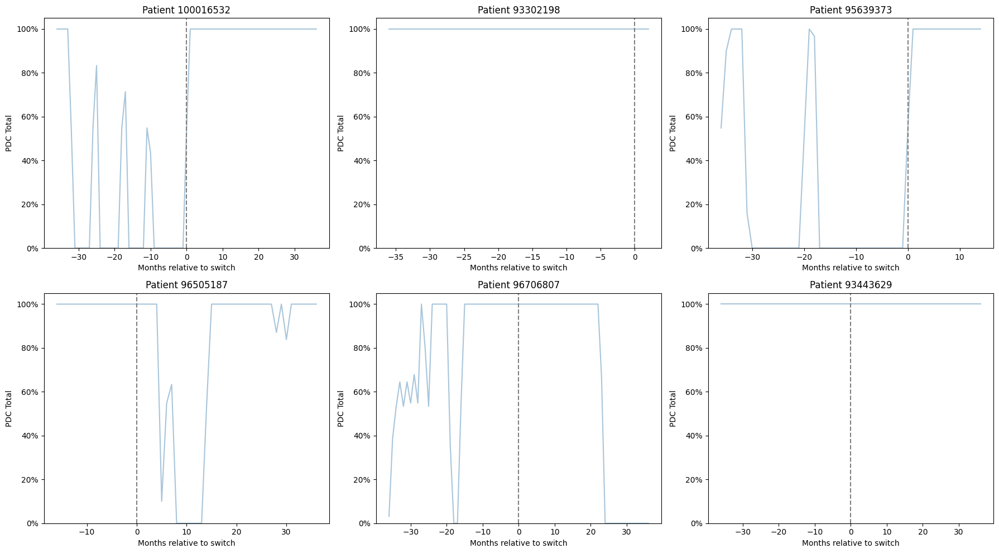

In [15]:
# Plot of several random patients
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

sample_ids = pdc_monthly_aligned['idCas'].drop_duplicates().sample(6, random_state=42)

for i, patient_id in enumerate(sample_ids):
    patient_data = pdc_monthly_aligned[pdc_monthly_aligned['idCas'] == patient_id]
    axes[i].plot(patient_data['months_to_switch'], patient_data['PDC_total'], 
                 color='#A8C5DA', linewidth=1.5)
    axes[i].axvline(x=0, color='grey', linestyle='--')
    axes[i].set_title(f'Patient {patient_id}')
    axes[i].set_xlabel('Months relative to switch')
    axes[i].set_ylabel('PDC Total')
    axes[i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    axes[i].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\pdc_random_patients.png', dpi=150)
plt.show()

In [16]:
# Flagging missed injections
# Get all LAI dispensing events for switchers
lai_events_23 = df_23_2016[df_23_2016['formulation_type'] == 'LAI'][['idCas', 'dispensing_date', 'DES_HIS_Producte', 'days_coverage']]
lai_events_25 = df_25_2016[df_25_2016['formulation_type'] == 'LAI'][['idCas', 'dispensing_date', '(HIS) Producte Desc', 'days_coverage']]

# Rename to common column names
lai_events_23 = lai_events_23.rename(columns={'DES_HIS_Producte': 'product'})
lai_events_25 = lai_events_25.rename(columns={'(HIS) Producte Desc': 'product'})

lai_all = pd.concat([lai_events_23, lai_events_25]).sort_values(['idCas', 'dispensing_date']).reset_index(drop=True)

# Calculate gaps per patient
records = []
for patient_id, group in lai_all.groupby('idCas'):
    group = group.sort_values('dispensing_date').reset_index(drop=True)
    for i in range(len(group) - 1):
        expected_next = group.loc[i, 'dispensing_date'] + pd.Timedelta(days=int(group.loc[i, 'days_coverage']))
        actual_next = group.loc[i+1, 'dispensing_date']
        gap_days = (actual_next - expected_next).days
        gap_weeks = gap_days / 7
        missed = gap_days > 14
        
        records.append({
            'idCas': patient_id,
            'injection_date': group.loc[i, 'dispensing_date'],
            'expected_next': expected_next,
            'actual_next': actual_next,
            'gap_days': gap_days,
            'gap_weeks': round(gap_weeks, 2),
            'missed': missed,
            'product': group.loc[i, 'product']
        })

gaps_df = pd.DataFrame(records)

# Add switch year
gaps_df = gaps_df.merge(switch_dates[['idCas', 'first_lai_date']], on='idCas', how='left')
gaps_df['switch_year'] = pd.to_datetime(gaps_df['first_lai_date']).dt.year
gaps_df['pre_post'] = gaps_df.apply(
    lambda row: 'post' if row['injection_date'] >= row['first_lai_date'] else 'pre', axis=1
)

print(gaps_df.head(10))
print(f"\nMissed injections: {gaps_df['missed'].sum()} / {len(gaps_df)} ({gaps_df['missed'].mean()*100:.1f}%)")
print(f"\nMean gap pre-switch: {gaps_df[gaps_df['pre_post']=='pre']['gap_weeks'].mean():.2f} weeks")
print(f"Mean gap post-switch: {gaps_df[gaps_df['pre_post']=='post']['gap_weeks'].mean():.2f} weeks")

      idCas injection_date expected_next actual_next  gap_days  gap_weeks  \
0  75851283     2019-11-15    2019-12-13  2019-11-15       -28      -4.00   
1  75851283     2019-11-15    2019-12-13  2019-11-15       -28      -4.00   
2  75851283     2019-11-15    2019-12-13  2019-11-15       -28      -4.00   
3  75851283     2019-11-15    2019-12-13  2019-12-15         2       0.29   
4  75851283     2019-12-15    2020-01-12  2019-12-15       -28      -4.00   
5  75851283     2019-12-15    2020-01-12  2019-12-15       -28      -4.00   
6  75851283     2019-12-15    2020-01-12  2019-12-15       -28      -4.00   
7  77532646     2019-10-15    2019-11-12  2019-10-15       -28      -4.00   
8  77532646     2019-10-15    2019-11-12  2019-10-15       -28      -4.00   
9  77532646     2019-10-15    2019-11-12  2019-10-15       -28      -4.00   

   missed                                            product first_lai_date  \
0   False  ABILIFY MAINTENA 400MG 1 VIAL POLVO +1 VIAL DI...     2019-11-

In [17]:
lai_all = lai_all.drop_duplicates(subset=['idCas', 'dispensing_date', 'product']).sort_values(['idCas', 'dispensing_date']).reset_index(drop=True)
print(lai_all.shape)

(19209, 4)


# Adh in trajectories, month per column
jan 2015 - dec 2017 (date of switching to LAI)

In [18]:
# Switchers between 2015-2017
switchers_1517 = pdc[
    (pdc['switcher'] == True) & 
    (pdc['first_lai_date'].dt.year.between(2015, 2017))
]['idCas'].unique()

print(f"N switchers 2015-2017: {len(switchers_1517)}")

N switchers 2015-2017: 1147


In [19]:
df_23_1517 = df_23_dispensats[df_23_dispensats['idCas'].isin(switchers_1517)].copy()
df_25_1517 = df_25_mhda[df_25_mhda['idCas'].isin(switchers_1517)].copy()

# Apply classification and dates
df_23_1517['formulation_type'] = df_23_1517['DES_HIS_Producte'].apply(classify_product)
df_23_1517['dispensing_date'] = df_23_1517['Any_Mes'].apply(anymes_to_date)
df_23_1517['days_coverage'] = df_23_1517.apply(
    lambda row: LAI_INTERVALS[row['DES_HIS_Producte']] 
    if row['formulation_type'] == 'LAI' 
    else (float(str(row['Nombre_DDD_Receptes_Dispensades']).replace(',', '.')) 
          if row['formulation_type'] == 'ORAL' else 0),
    axis=1
)

df_25_1517['formulation_type'] = df_25_1517['(HIS) Producte Desc'].apply(classify_product)
df_25_1517['dispensing_date'] = df_25_1517['Any_Mes'].apply(anymes_to_date)
df_25_1517['days_coverage'] = df_25_1517.apply(
    lambda row: LAI_INTERVALS[row['(HIS) Producte Desc']] 
    if row['formulation_type'] == 'LAI' else 0,
    axis=1
)

print(df_23_1517['formulation_type'].value_counts())
print(df_25_1517['formulation_type'].value_counts())

formulation_type
ORAL                75980
LAI                 73863
IMMEDIATE_ACTION      132
Name: count, dtype: int64
formulation_type
ORAL    1725
LAI      253
Name: count, dtype: int64


In [20]:
import calendar

# Get first LAI date per patient (month 0)
first_lai_dates = pdc[pdc['idCas'].isin(switchers_1517)][['idCas', 'first_lai_date']].drop_duplicates()
first_lai_dates['first_lai_date'] = pd.to_datetime(first_lai_dates['first_lai_date'])

# Combine dispensing tables
all_disp = pd.concat([
    df_23_1517[['idCas', 'dispensing_date', 'days_coverage', 'formulation_type']],
    df_25_1517[['idCas', 'dispensing_date', 'days_coverage', 'formulation_type']]
])
all_disp = all_disp[all_disp['formulation_type'].isin(['ORAL', 'LAI'])]
all_disp = all_disp.merge(first_lai_dates, on='idCas', how='left')

# Build daily calendar per patient
records = []
for _, row in all_disp.iterrows():
    start = row['dispensing_date']
    end = start + pd.Timedelta(days=int(row['days_coverage']) - 1)
    for day in pd.date_range(start, end):
        records.append({'idCas': row['idCas'], 'date': day, 'first_lai_date': row['first_lai_date']})

df_days = pd.DataFrame(records).drop_duplicates(subset=['idCas', 'date'])

# Calculate relative month (0 to 11)
df_days['day_relative'] = (df_days['date'] - df_days['first_lai_date']).dt.days
df_days = df_days[(df_days['day_relative'] >= 0) & (df_days['day_relative'] < 365)]
df_days['month'] = (df_days['day_relative'] // 30) + 1

# Monthly PDC
monthly = df_days.groupby(['idCas', 'month']).size().reset_index(name='days_covered')
monthly['PDC'] = (monthly['days_covered'] / 30).clip(upper=1.0)

# Pivot to wide format
df_wide = monthly.pivot(index='idCas', columns='month', values='PDC').fillna(0)
df_wide.columns = [f'Month_{col}' for col in df_wide.columns]

# Keep only patients with all 12 months
df_wide = df_wide[[f'Month_{i}' for i in range(1, 13)]].dropna()

print(f"Patients with full 12-month follow-up: {len(df_wide)}")
print(df_wide.head())

Patients with full 12-month follow-up: 1147
           Month_1   Month_2   Month_3   Month_4   Month_5   Month_6  \
idCas                                                                  
83951106  0.933333  0.933333  0.933333  0.933333  0.566667  0.000000   
83996724  0.933333  0.600000  0.000000  0.000000  0.000000  0.000000   
84015456  0.933333  0.966667  0.966667  0.933333  0.900000  0.033333   
84051362  0.933333  0.933333  0.933333  0.933333  0.900000  0.933333   
84068869  0.933333  0.000000  0.000000  0.933333  1.000000  1.000000   

           Month_7   Month_8   Month_9  Month_10  Month_11  Month_12  
idCas                                                                 
83951106  0.900000  0.933333  0.900000  0.933333  0.900000       0.9  
83996724  0.000000  0.000000  0.000000  0.000000  0.000000       0.0  
84015456  0.000000  0.466667  0.466667  0.466667  0.866667       0.9  
84051362  0.900000  0.900000  0.100000  0.000000  0.000000       0.0  
84068869  0.366667  0.933

In [21]:
# POST-SWITCH: already done above as df_wide
# PRE-SWITCH: 12 months before first LAI

records_pre = []
for _, row in all_disp.iterrows():
    start = row['dispensing_date']
    end = start + pd.Timedelta(days=int(row['days_coverage']) - 1)
    for day in pd.date_range(start, end):
        records_pre.append({'idCas': row['idCas'], 'date': day, 'first_lai_date': row['first_lai_date']})

df_days_pre = pd.DataFrame(records_pre).drop_duplicates(subset=['idCas', 'date'])

# Calculate relative day (negative = before switch)
df_days_pre['day_relative'] = (df_days_pre['date'] - df_days_pre['first_lai_date']).dt.days
df_days_pre = df_days_pre[(df_days_pre['day_relative'] >= -365) & (df_days_pre['day_relative'] < 0)]
df_days_pre['month'] = (df_days_pre['day_relative'] // 30)  # -12 to -1

# Monthly PDC
monthly_pre = df_days_pre.groupby(['idCas', 'month']).size().reset_index(name='days_covered')
monthly_pre['PDC'] = (monthly_pre['days_covered'] / 30).clip(upper=1.0)

# Pivot to wide format
df_wide_pre = monthly_pre.pivot(index='idCas', columns='month', values='PDC').fillna(0)
df_wide_pre.columns = [f'Month_{col}' for col in df_wide_pre.columns]

# Keep only patients with all 12 pre-switch months
pre_cols = [f'Month_{i}' for i in range(-12, 0)]
df_wide_pre = df_wide_pre[pre_cols].dropna()

print(f"Patients with full 12-month pre-switch: {len(df_wide_pre)}")

# COMBINED: -12 to +12
common_ids = df_wide.index.intersection(df_wide_pre.index)
df_wide_combined = pd.concat([df_wide_pre.loc[common_ids], df_wide.loc[common_ids]], axis=1)

print(f"Patients with full 24-month window: {len(df_wide_combined)}")
print(df_wide_combined.head())

Patients with full 12-month pre-switch: 1025
Patients with full 24-month window: 1025
          Month_-12  Month_-11  Month_-10  Month_-9  Month_-8  Month_-7  \
idCas                                                                     
83951106   1.000000   1.000000   0.633333  0.000000       0.0  0.000000   
83996724   0.000000   0.000000   0.000000  0.000000       0.0  0.000000   
84015456   0.000000   0.000000   0.000000  0.000000       0.0  0.000000   
84051362   0.000000   0.000000   0.000000  0.000000       0.0  0.000000   
84068869   0.133333   0.666667   0.533333  0.066667       1.0  0.266667   

          Month_-6  Month_-5  Month_-4  Month_-3  ...   Month_3   Month_4  \
idCas                                             ...                       
83951106       0.0  0.066667  0.466667  0.900000  ...  0.933333  0.933333   
83996724       0.0  0.000000  0.000000  0.000000  ...  0.000000  0.000000   
84015456       0.0  0.000000  0.000000  0.033333  ...  0.966667  0.933333   
840

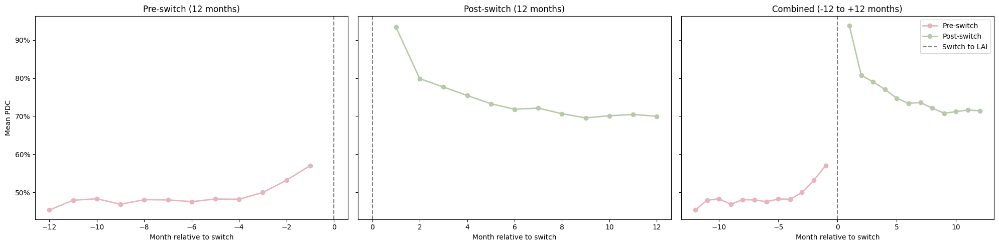

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

custom2 = ['#E8B4BC', '#B7C9A8', '#A8C5DA']

# Pre-switch mean trajectory
pre_mean = df_wide_pre.mean()
axes[0].plot(range(-12, 0), pre_mean.values, color=custom2[0], linewidth=2, marker='o')
axes[0].axvline(x=0, color='grey', linestyle='--', label='Switch to LAI')
axes[0].set_title('Pre-switch (12 months)')
axes[0].set_xlabel('Month relative to switch')
axes[0].set_ylabel('Mean PDC')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))

# Post-switch mean trajectory
post_mean = df_wide.mean()
axes[1].plot(range(1, 13), post_mean.values, color=custom2[1], linewidth=2, marker='o')
axes[1].axvline(x=0, color='grey', linestyle='--', label='Switch to LAI')
axes[1].set_title('Post-switch (12 months)')
axes[1].set_xlabel('Month relative to switch')

# Combined
combined_mean = df_wide_combined.mean()
axes[2].plot(range(-12, 0), combined_mean.values[:12], color=custom2[0], linewidth=2, marker='o', label='Pre-switch')
axes[2].plot(range(1, 13), combined_mean.values[12:], color=custom2[1], linewidth=2, marker='o', label='Post-switch')
axes[2].axvline(x=0, color='grey', linestyle='--', label='Switch to LAI')
axes[2].set_title('Combined (-12 to +12 months)')
axes[2].set_xlabel('Month relative to switch')
axes[2].legend()

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\pdc_pre_post_trajectory.png', dpi=150)
plt.show()

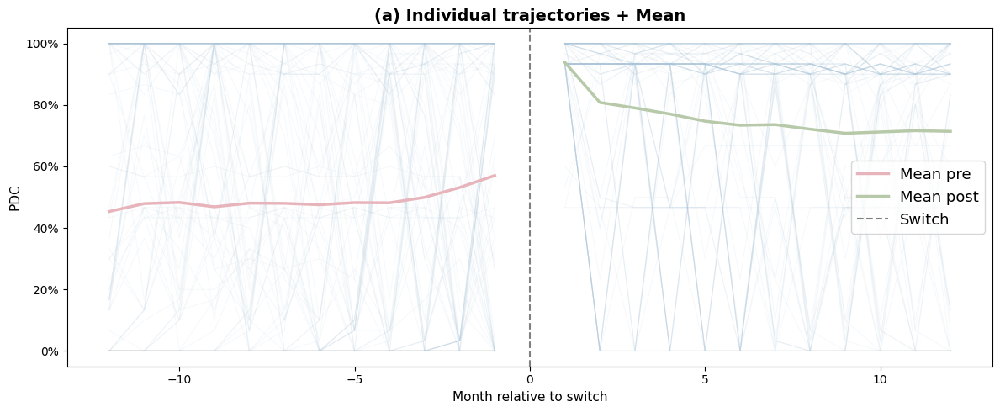

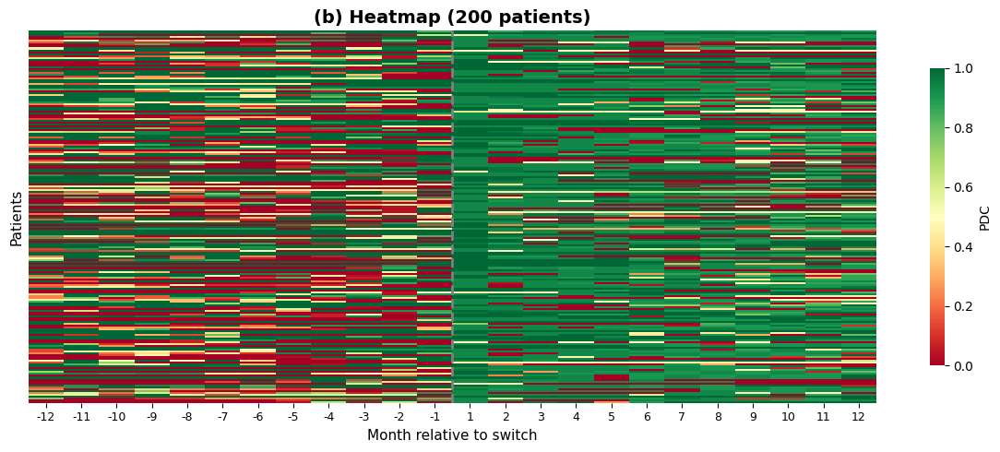

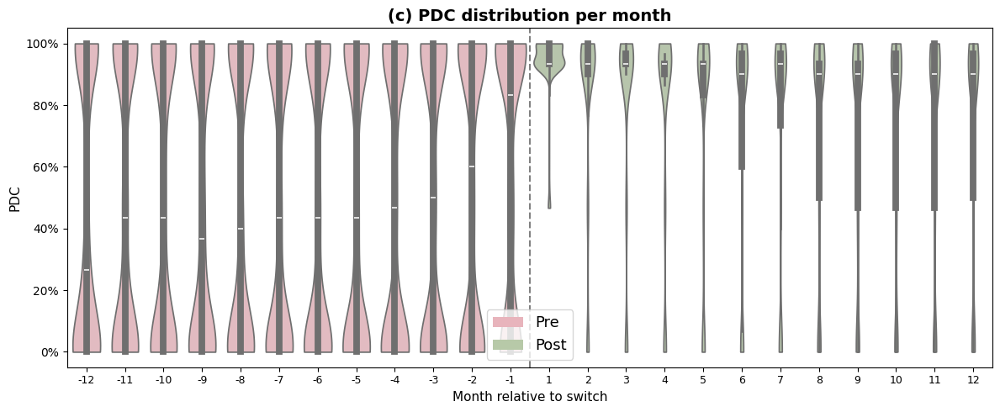

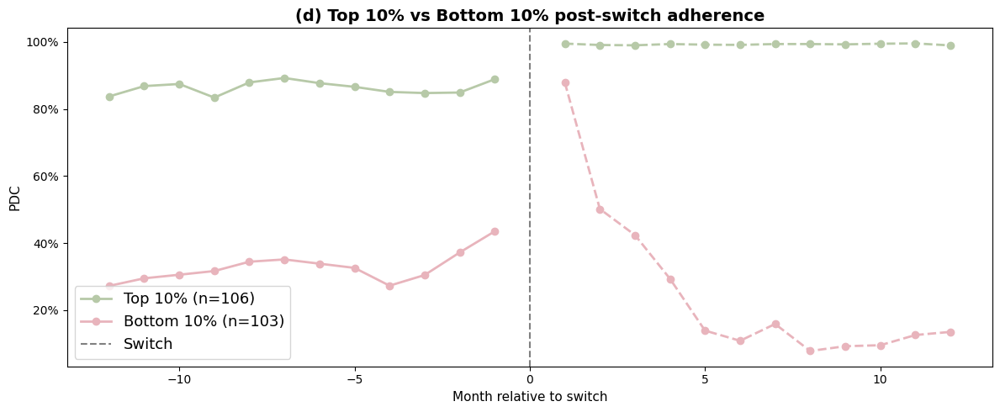

In [23]:
fig_size = (12, 5)
legend_fontsize = 13
title_fontsize = 14

# ── Plot A: Spaghetti ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=fig_size)
sample_ids = df_wide_combined.sample(100, random_state=42).index
for pid in sample_ids:
    ax.plot(range(-12, 13),
            list(df_wide_combined.loc[pid, [f'Month_{i}' for i in range(-12, 0)]].values) +
            [None] +
            list(df_wide_combined.loc[pid, [f'Month_{i}' for i in range(1, 13)]].values),
            color=custom2[2], alpha=0.1, linewidth=0.8)
ax.plot(range(-12, 0), df_wide_combined[[f'Month_{i}' for i in range(-12, 0)]].mean().values,
        color=custom2[0], linewidth=2.5, label='Mean pre')
ax.plot(range(1, 13), df_wide_combined[[f'Month_{i}' for i in range(1, 13)]].mean().values,
        color=custom2[1], linewidth=2.5, label='Mean post')
ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
ax.set_title('(a) Individual trajectories + Mean', fontsize=title_fontsize, fontweight='bold')
ax.set_xlabel('Month relative to switch', fontsize=11)
ax.set_ylabel('PDC', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend(fontsize=legend_fontsize)
plt.tight_layout()
plt.savefig('plot_a_spaghetti.png', dpi=200, bbox_inches='tight')
plt.show()

# Plot B: Heatmap
fig, ax = plt.subplots(figsize=fig_size)
heatmap_data = df_wide_combined.sample(200, random_state=42)
sns.heatmap(heatmap_data, ax=ax, cmap='RdYlGn', vmin=0, vmax=1,
            xticklabels=list(range(-12, 0)) + list(range(1, 13)),
            yticklabels=False, cbar_kws={'label': 'PDC', 'shrink': 0.8})
ax.axvline(x=12, color='grey', linestyle='--', linewidth=2)
ax.set_title('(b) Heatmap (200 patients)', fontsize=title_fontsize, fontweight='bold')
ax.set_xlabel('Month relative to switch', fontsize=11)
ax.set_ylabel('Patients', fontsize=11)
ax.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.savefig('plot_b_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

# Plot C: Violin
fig, ax = plt.subplots(figsize=fig_size)
combined_long = df_wide_combined.reset_index().melt(id_vars='idCas', var_name='month', value_name='PDC')
combined_long['month_num'] = combined_long['month'].str.extract(r'(-?\d+)').astype(int)
combined_long = combined_long[combined_long['month_num'].isin(range(-12, 13))]
combined_long['period'] = combined_long['month_num'].apply(lambda x: 'Pre' if x < 0 else 'Post')
combined_long['PDC'] = combined_long['PDC'].clip(lower=0, upper=1)

sns.violinplot(data=combined_long, x='month_num', y='PDC', hue='period',
               palette={'Pre': custom2[0], 'Post': custom2[1]}, ax=ax, legend=False, cut=0)
ax.axvline(x=11.5, color='grey', linestyle='--')
ax.set_title('(c) PDC distribution per month', fontsize=title_fontsize, fontweight='bold')
ax.set_xlabel('Month relative to switch', fontsize=11)
ax.set_ylabel('PDC', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.tick_params(axis='x', labelsize=9)

# Manual legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=custom2[0], label='Pre'), Patch(facecolor=custom2[1], label='Post')]
ax.legend(handles=legend_elements, fontsize=legend_fontsize)
plt.tight_layout()
plt.savefig('plot_c_violin.png', dpi=200, bbox_inches='tight')
plt.show()

# Plot D: Top vs Bottom 10%
fig, ax = plt.subplots(figsize=fig_size)
mean_post = df_wide_combined[[f'Month_{i}' for i in range(1, 13)]].mean(axis=1)
top10    = df_wide_combined[mean_post >= mean_post.quantile(0.9)]
bottom10 = df_wide_combined[mean_post <= mean_post.quantile(0.1)]

ax.plot(range(-12, 0), top10[[f'Month_{i}' for i in range(-12, 0)]].mean().values,
        color=custom2[1], linewidth=2, marker='o', label=f'Top 10% (n={len(top10)})')
ax.plot(range(1, 13), top10[[f'Month_{i}' for i in range(1, 13)]].mean().values,
        color=custom2[1], linewidth=2, marker='o', linestyle='--')
ax.plot(range(-12, 0), bottom10[[f'Month_{i}' for i in range(-12, 0)]].mean().values,
        color=custom2[0], linewidth=2, marker='o', label=f'Bottom 10% (n={len(bottom10)})')
ax.plot(range(1, 13), bottom10[[f'Month_{i}' for i in range(1, 13)]].mean().values,
        color=custom2[0], linewidth=2, marker='o', linestyle='--')
ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
ax.set_title('(d) Top 10% vs Bottom 10% post-switch adherence', fontsize=title_fontsize, fontweight='bold')
ax.set_xlabel('Month relative to switch', fontsize=11)
ax.set_ylabel('PDC', fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend(fontsize=legend_fontsize)
plt.tight_layout()
plt.savefig('plot_d_top_bottom.png', dpi=200, bbox_inches='tight')
plt.show()

- **Spaghetti**: The vertical lines pre-switch confirm irregular oral dispensing patterns. Post-switch PDC jumps and stabilizes around 70-80% — the LAI effect is clear.
- **Heatmap**: You can already see two main groups emerging — a green block (high adherence throughout) and a mixed red/green block (irregular pre-switch, green post-switch).
- **Violin**: Pre-switch distribution is very bimodal (0% or 100%) — patients either pick up medication or don't. Post-switch it becomes much more concentrated around 90-100%.
- **Top vs Bottom 10%**: The bottom 10% actually had decent pre-switch adherence (~30-40%) but drops dramatically after switching to LAI. This could mean they abandoned LAI quickly after starting.

In [24]:
bottom10_ids = bottom10.index.tolist()

In [25]:
bottom10_disp = all_disp[all_disp['idCas'].isin(bottom10_ids)].copy()
bottom10_disp['day_relative'] = (bottom10_disp['dispensing_date'] - bottom10_disp['first_lai_date']).dt.days

post_lai = bottom10_disp[
    (bottom10_disp['day_relative'] >= 0) & 
    (bottom10_disp['formulation_type'] == 'LAI')
].groupby('idCas').size().reset_index(name='n_lai_post')

print(post_lai['n_lai_post'].value_counts().sort_index())
print(f"\nMean LAI dispensings post-switch: {post_lai['n_lai_post'].mean():.2f}")

n_lai_post
1       1
2      12
3       1
4      15
6       3
7       1
8       7
9       1
10     12
12      6
13      1
14      3
16      5
17      1
18      3
24      4
26      5
28      1
34      1
36      2
38      1
40      1
44      1
46      1
50      2
52      1
60      3
66      2
78      1
94      1
96      1
98      1
106     1
120     1
Name: count, dtype: int64

Mean LAI dispensings post-switch: 20.97


In [26]:
sample_bottom = bottom10_ids[0]
print(df_wide_combined.loc[sample_bottom])

Month_-12    0.000000
Month_-11    0.000000
Month_-10    0.000000
Month_-9     0.000000
Month_-8     0.000000
Month_-7     0.000000
Month_-6     0.000000
Month_-5     0.000000
Month_-4     0.000000
Month_-3     0.000000
Month_-2     0.033333
Month_-1     0.566667
Month_1      0.933333
Month_2      0.600000
Month_3      0.000000
Month_4      0.000000
Month_5      0.000000
Month_6      0.000000
Month_7      0.000000
Month_8      0.000000
Month_9      0.000000
Month_10     0.000000
Month_11     0.000000
Month_12     0.000000
Name: 83996724, dtype: float64


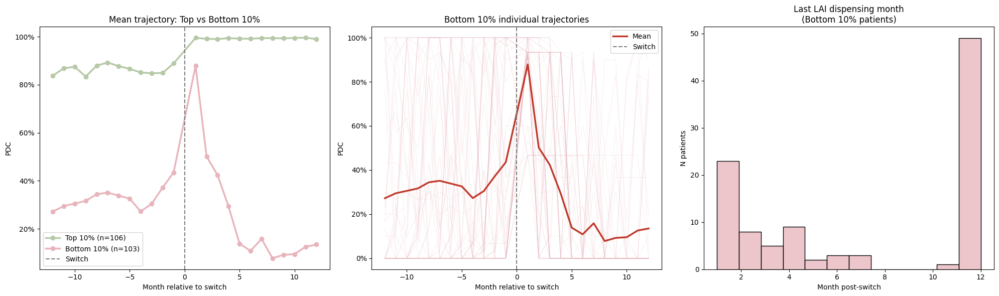

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

custom2 = ['#E8B4BC', '#B7C9A8', '#A8C5DA']

# 1. Mean trajectory bottom 10% vs top 10%
ax = axes[0]
months = list(range(-12, 0)) + list(range(1, 13))
top_mean = top10.mean().values
bottom_mean = bottom10.mean().values

ax.plot(months, top_mean, color=custom2[1], linewidth=2.5, marker='o', label=f'Top 10% (n={len(top10)})')
ax.plot(months, bottom_mean, color=custom2[0], linewidth=2.5, marker='o', label=f'Bottom 10% (n={len(bottom10)})')
ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
ax.set_title('Mean trajectory: Top vs Bottom 10%')
ax.set_xlabel('Month relative to switch')
ax.set_ylabel('PDC')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend()

# 2. Spaghetti bottom 10% only
ax = axes[1]
sample_bottom = bottom10.sample(min(50, len(bottom10)), random_state=42)
for pid in sample_bottom.index:
    ax.plot(months, sample_bottom.loc[pid].values,
            color=custom2[0], alpha=0.2, linewidth=0.8)
ax.plot(months, bottom_mean, color='#C0392B', linewidth=2.5, label='Mean')
ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
ax.set_title('Bottom 10% individual trajectories')
ax.set_xlabel('Month relative to switch')
ax.set_ylabel('PDC')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
ax.legend()

# 3. Distribution of last LAI dispensing month for bottom 10%
ax = axes[2]
last_lai_month = []
for pid in bottom10_ids:
    patient_disp = bottom10_disp[
        (bottom10_disp['idCas'] == pid) & 
        (bottom10_disp['formulation_type'] == 'LAI') &
        (bottom10_disp['day_relative'] >= 0)
    ]
    if not patient_disp.empty:
        last_day = patient_disp['day_relative'].max()
        last_lai_month.append(min(last_day // 30 + 1, 12))

sns.histplot(last_lai_month, bins=12, color=custom2[0], ax=ax)
ax.set_title('Last LAI dispensing month\n(Bottom 10% patients)')
ax.set_xlabel('Month post-switch')
ax.set_ylabel('N patients')

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\bottom10_analysis.png', dpi=150)
plt.show()

In [28]:
# Clustring continuous PDC
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from sklearn.metrics import silhouette_score
import numpy as np

# Prepare data for tslearn (3D array: n_patients, n_timepoints, 1)
X = df_wide_combined.values
X_3d = X.reshape((X.shape[0], X.shape[1], 1))

# Test k=2 to 5 and compute silhouette scores
silhouette_scores = {}

for k in range(2, 6):
    model = TimeSeriesKMeans(n_clusters=k, metric="euclidean", random_state=42, n_jobs=-1)
    labels = model.fit_predict(X_3d)
    score = silhouette_score(X, labels)
    silhouette_scores[k] = score
    print(f"k={k}: silhouette={score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nBest k: {best_k}")

c:\Users\laiar\AppData\Local\Programs\Python\Python310\lib\site-packages\tslearn\bases\bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


k=2: silhouette=0.2724
k=3: silhouette=0.2571
k=4: silhouette=0.2110
k=5: silhouette=0.1968

Best k: 2


cluster
1    596
0    429
Name: count, dtype: int64


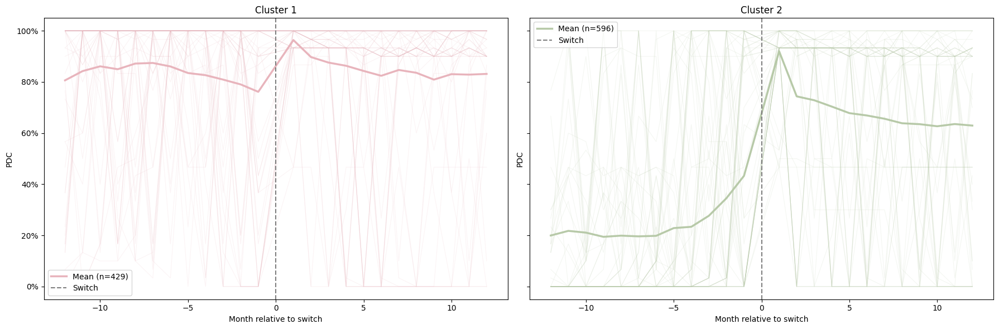

In [29]:
# Fit final model with k=2
model_final = TimeSeriesKMeans(n_clusters=2, metric="euclidean", random_state=42, n_jobs=-1)
labels = model_final.fit_predict(X_3d)

# Add cluster labels to df_wide_combined
df_wide_combined['cluster'] = labels

# Cluster sizes
print(df_wide_combined['cluster'].value_counts())

# Plot cluster trajectories
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

months = list(range(-12, 0)) + list(range(1, 13))
cols = [f'Month_{i}' for i in range(-12, 0)] + [f'Month_{i}' for i in range(1, 13)]

for cluster_id in range(2):
    ax = axes[cluster_id]
    cluster_data = df_wide_combined[df_wide_combined['cluster'] == cluster_id]
    cluster_mean = cluster_data[cols].mean().values
    
    # Spaghetti
    sample = cluster_data.sample(min(50, len(cluster_data)), random_state=42)
    for pid in sample.index:
        ax.plot(months, sample.loc[pid, cols].values,
                color=custom2[cluster_id], alpha=0.15, linewidth=0.8)
    
    # Mean line
    ax.plot(months, cluster_mean, color=custom2[cluster_id], 
            linewidth=2.5, label=f'Mean (n={len(cluster_data)})')
    ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
    ax.set_title(f'Cluster {cluster_id + 1}')
    ax.set_xlabel('Month relative to switch')
    ax.set_ylabel('PDC')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax.legend()

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\clusters_k2.png', dpi=150)
plt.show()

cluster_k3
0    420
1    394
2    211
Name: count, dtype: int64


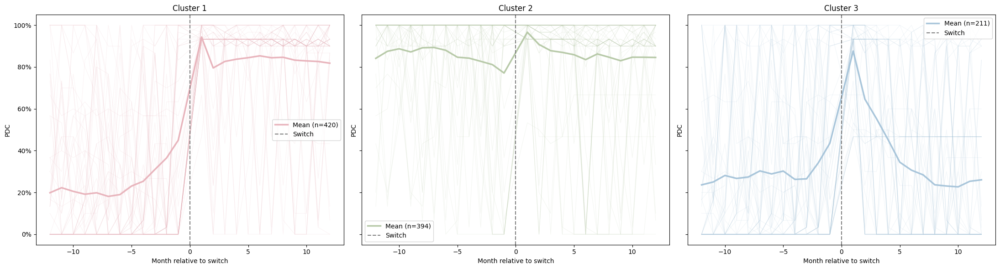

In [30]:
# Fit model with k=3
model_k3 = TimeSeriesKMeans(n_clusters=3, metric="euclidean", random_state=42, n_jobs=-1)
labels_k3 = model_k3.fit_predict(X_3d)

df_wide_combined['cluster_k3'] = labels_k3
print(df_wide_combined['cluster_k3'].value_counts())

# Plot
fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=True)

for cluster_id in range(3):
    ax = axes[cluster_id]
    cluster_data = df_wide_combined[df_wide_combined['cluster_k3'] == cluster_id]
    cluster_mean = cluster_data[cols].mean().values
    
    # Spaghetti
    sample = cluster_data.sample(min(50, len(cluster_data)), random_state=42)
    for pid in sample.index:
        ax.plot(months, sample.loc[pid, cols].values,
                color=custom2[cluster_id], alpha=0.15, linewidth=0.8)
    
    # Mean line
    ax.plot(months, cluster_mean, color=custom2[cluster_id],
            linewidth=2.5, label=f'Mean (n={len(cluster_data)})')
    ax.axvline(x=0, color='grey', linestyle='--', label='Switch')
    ax.set_title(f'Cluster {cluster_id + 1}')
    ax.set_xlabel('Month relative to switch')
    ax.set_ylabel('PDC')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax.legend()

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\clusters_k3.png', dpi=150)
plt.show()

- **Cluster 1 (pink, n=420) — "Improvers"**:

Low pre-switch adherence (~20%)
Big jump at switch → stabilizes at ~85% post-switch
LAI clearly helped these patients

- **Cluster 2 (green, n=394) — "Chronically adherent"**:

Already high adherence pre-switch (~85%)
Maintains high adherence post-switch (~85%)
LAI didn't change much

- **Cluster 3 (blue, n=211) — "Dropouts/Decliners"**:

Moderate pre-switch adherence (~25%)
Brief spike at month 0, then drops back to ~15-20%
LAI didn't help

In [31]:
# Binary classification: High vs Low adherence post-switch
# Create binary version (1 if PDC >= 0.80, 0 if not)
df_wide_binary = df_wide_combined[cols].applymap(lambda x: 1 if x >= 0.80 else 0)
df_wide_binary.index = df_wide_combined.index

# Prepare for tslearn
X_bin = df_wide_binary.values
X_bin_3d = X_bin.reshape((X_bin.shape[0], X_bin.shape[1], 1))

# Test k=2 to 5
silhouette_scores_bin = {}

for k in range(2, 6):
    model = TimeSeriesKMeans(n_clusters=k, metric="euclidean", random_state=42, n_jobs=-1)
    labels = model.fit_predict(X_bin_3d)
    score = silhouette_score(X_bin, labels)
    silhouette_scores_bin[k] = score
    print(f"k={k}: silhouette={score:.4f}")

best_k_bin = max(silhouette_scores_bin, key=silhouette_scores_bin.get)
print(f"\nBest k: {best_k_bin}")

C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\1526799400.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_wide_binary = df_wide_combined[cols].applymap(lambda x: 1 if x >= 0.80 else 0)


k=2: silhouette=0.2643
k=3: silhouette=0.2697
k=4: silhouette=0.2088
k=5: silhouette=0.2118

Best k: 3


In [32]:
# Mean PDC per cluster per month
cluster_means = df_wide_combined.groupby('cluster_k3')[cols].mean()
cluster_means.index = ['Improvers', 'Chronically adherent', 'Dropouts']
cluster_means.columns = list(range(-12, 0)) + list(range(1, 13))

print(cluster_means.round(3).to_string())

                        -12    -11    -10    -9     -8     -7     -6     -5     -4     -3     -2     -1      1      2      3      4      5      6      7      8      9      10     11     12
Improvers             0.199  0.223  0.205  0.192  0.198  0.181  0.190  0.231  0.253  0.310  0.365  0.450  0.943  0.796  0.827  0.837  0.845  0.853  0.844  0.847  0.833  0.829  0.826  0.818
Chronically adherent  0.842  0.875  0.887  0.872  0.892  0.893  0.880  0.847  0.842  0.827  0.811  0.771  0.966  0.908  0.878  0.870  0.859  0.835  0.863  0.847  0.830  0.847  0.847  0.846
Dropouts              0.236  0.250  0.281  0.267  0.274  0.303  0.289  0.302  0.262  0.265  0.341  0.436  0.876  0.647  0.553  0.452  0.345  0.306  0.284  0.236  0.231  0.227  0.253  0.260


In [33]:
df_wide_combined[cols] = df_wide_combined[cols].round(3)

In [31]:
df_wide_combined[cols] = df_wide_combined[cols].round(3)
df_wide_combined.to_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\csv merged\pdc_monthly_wide_clusters.csv')
print("Saved!")

Saved!


In [34]:
# Model 4 clusters
model_k4 = TimeSeriesKMeans(n_clusters=4, metric="euclidean", random_state=42, n_jobs=-1)
labels_k4 = model_k4.fit_predict(X_3d)

df_wide_combined['cluster_k4'] = labels_k4

cluster_names_k4 = {0: 'Cluster 1', 1: 'Cluster 2', 2: 'Cluster 3', 3: 'Cluster 4'}
print(df_wide_combined['cluster_k4'].map(cluster_names_k4).value_counts())

cluster_k4
Cluster 1    321
Cluster 2    319
Cluster 4    198
Cluster 3    187
Name: count, dtype: int64


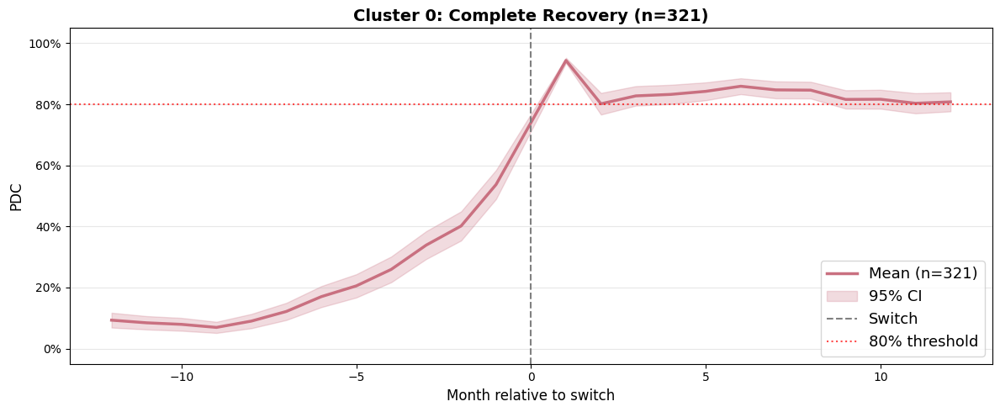

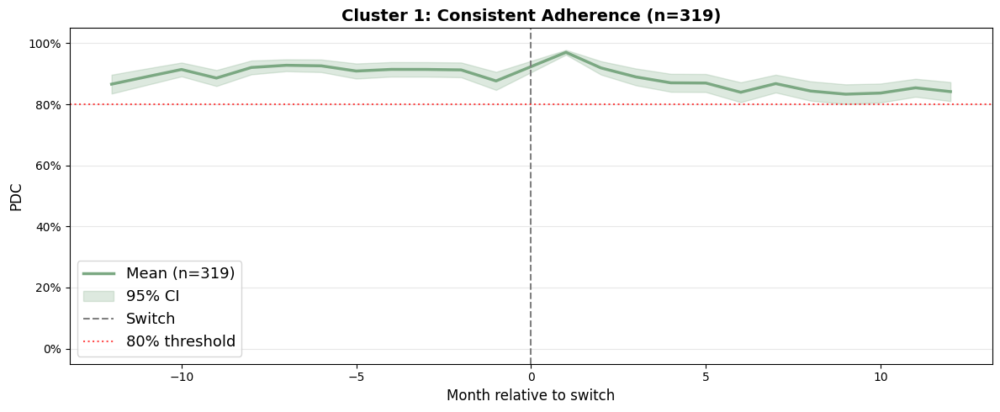

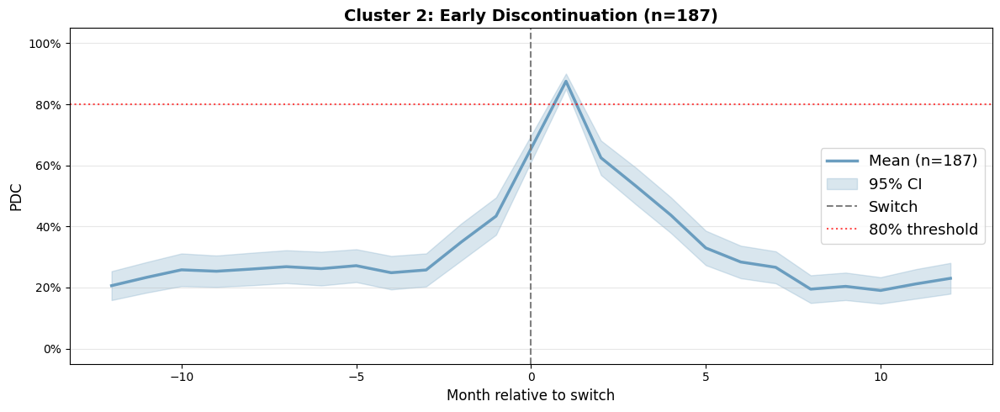

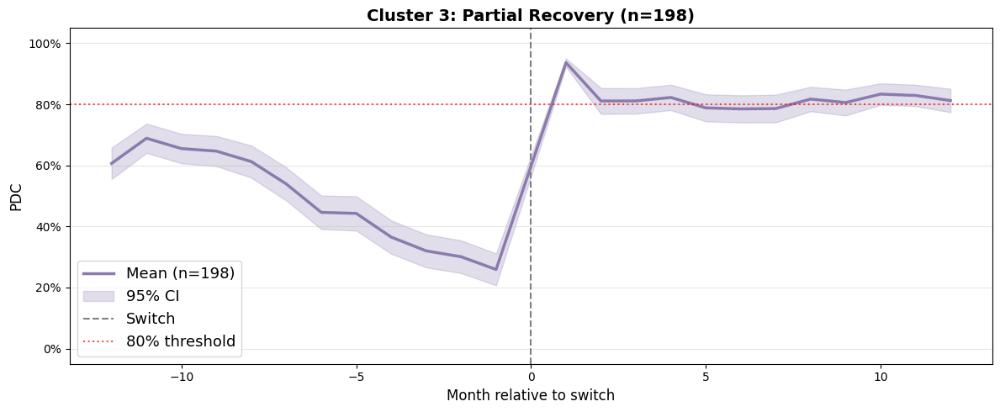

In [35]:
import matplotlib.pyplot as plt
import numpy as np

custom_k4 = ['#C97080', '#7BA882', '#6A9DBF', '#8B7BAD']  # darkened versions
legend_fontsize = 13
title_fontsize = 14

cluster_names_k4 = {
    0: 'Complete Recovery',
    1: 'Consistent Adherence',
    2: 'Early Discontinuation',
    3: 'Partial Recovery'
}

months = list(range(-12, 0)) + list(range(1, 13))
cols = [f'Month_{i}' for i in range(-12, 0)] + [f'Month_{i}' for i in range(1, 13)]

for cluster_id in range(4):
    fig, ax = plt.subplots(figsize=(12, 5))
    cluster_data = df_wide_combined[df_wide_combined['cluster_k4'] == cluster_id]
    cluster_vals = cluster_data[cols].values
    
    cluster_mean = cluster_vals.mean(axis=0)
    n = len(cluster_data)
    se = cluster_vals.std(axis=0) / np.sqrt(n)
    ci95 = 1.96 * se

    # Mean line
    ax.plot(months, cluster_mean,
            color=custom_k4[cluster_id], linewidth=2.5,
            label=f'Mean (n={n})')

    # 95% CI shading
    ax.fill_between(months,
                    cluster_mean - ci95,
                    cluster_mean + ci95,
                    color=custom_k4[cluster_id], alpha=0.25,
                    label='95% CI')

    ax.axvline(x=0, color='grey', linestyle='--', linewidth=1.5, label='Switch')
    ax.axhline(y=0.80, color='red', linestyle=':', linewidth=1.5, alpha=0.7, label='80% threshold')

    ax.set_title(f'Cluster {cluster_id}: {cluster_names_k4[cluster_id]} (n={n})',
                 fontsize=title_fontsize, fontweight='bold')
    ax.set_xlabel('Month relative to switch', fontsize=12)
    ax.set_ylabel('PDC', fontsize=12)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=legend_fontsize)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'cluster_{cluster_id}_{cluster_names_k4[cluster_id].replace(" ", "_")}.png',
                dpi=200, bbox_inches='tight')
    plt.show()

- **Cluster 1 (pink, n=321) — "LAI Improvers"**:

    - Very low pre-switch adherence (~5-10%)
    - Sharp jump at switch → stabilizes at ~85% post-switch
    - LAI clearly helped these poorly adherent patients

- **Cluster 2 (green, n=319) — "Chronically Adherent"**:

    - Already high adherence pre-switch (~85%)
    - Maintains high adherence post-switch (~85%)
    - LAI didn't change much, already stable

- **Cluster 3 (blue, n=187) — "Early Dropouts"**:

    - Low-moderate pre-switch adherence (~20%)
    - Brief spike at month 0, then drops back to ~20%
    - Abandoned treatment quickly and LAI didn't improve adherence

- **Cluster 4 (purple, n=198) — "Moderate Improvers"**:

    - Variable pre-switch adherence, not increasing more than 60%
    - Improved moderately with LAI but didn't reach the 80% threshold consistently
    - Cluster for previously adherent on oral who worsened with LAI and turned out to still improve

In [36]:
print(df_wide_combined['cluster_k4'].value_counts().sort_index())

cluster_k4
0    321
1    319
2    187
3    198
Name: count, dtype: int64


In [38]:
# Make sure cluster_k4 is in df_wide_combined
print(df_wide_combined['cluster_k4'].value_counts())

# Reload the CSV and add cluster_k4
pdc_switchers_csv = pd.read_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\pdc_tables\pdc_monthly_wide_clusters.csv')
pdc_switchers_csv = pdc_switchers_csv.merge(
    df_wide_combined[['cluster_k4']].reset_index(), 
    on='idCas', 
    how='left'
)
pdc_switchers_csv.to_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\pdc_tables\pdc_monthly_wide_clusters.csv', index=False)
print("Saved!")
print(pdc_switchers_csv.columns.tolist())

cluster_k4
0    321
1    319
3    198
2    187
Name: count, dtype: int64
Saved!
['idCas', 'Month_-12', 'Month_-11', 'Month_-10', 'Month_-9', 'Month_-8', 'Month_-7', 'Month_-6', 'Month_-5', 'Month_-4', 'Month_-3', 'Month_-2', 'Month_-1', 'Month_1', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11', 'Month_12', 'cluster_k4_x', 'cluster_k4_y', 'cluster_k4']


## Comparing to visits

In [39]:
df_urg=pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\Datos_padris_schizo\urg_epi_dx_proc_schizophrenia.csv")
df_sma=pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\Datos_padris_schizo\sma_cap_dx_schizophrenia.csv")
df_smh=pd.read_csv(r"C:\Users\laiar\Desktop\DATOS_PADRIS_nets\Datos_padris_schizo\smh_epi_dx_proc_schizophrenia.csv")

In [40]:
print(df_urg.columns.tolist())
print(df_sma.columns.tolist())
print(df_smh.columns.tolist())

['idCas', 'id_cmbd', 'dat_ini', 'dat_fi', 'cod_proc_ing', 'desc_proc_ing', 'cod_tip_up_desti', 'desc_tip_up_desti', 'pos_dx_1', 'desc_dx_1', 'pos_dx_2', 'desc_dx_2', 'pos_dx_3', 'desc_dx_3', 'pos_dx_4', 'desc_dx_4', 'pos_proc_0', 'desc_proc_0', 'pos_proc_1', 'desc_proc_1', 'pos_proc_2', 'desc_proc_2', 'pos_proc_3', 'desc_proc_3']
['idCas', 'id_cmbd', 'Data inici assistència', 'Procedència ingrés', 'Pro_ingres_Codi', 'Data fi assistència', 'Visites en centres ambulatoris de salut mental', 'pos_diag_1', 'diag_1', 'pos_diag_2', 'diag_2', 'pos_diag_3', 'diag_3', 'pos_diag_4', 'diag_4']
['idCas', 'id_cmbd', 'dat_ini', 'pos_dx_1', 'desc_dx_1', 'pos_dx_2', 'desc_dx_2', 'pos_dx_3', 'desc_dx_3', 'pos_dx_4', 'desc_dx_4', 'cod_proc', 'desc_proc']


In [43]:
# Filtering per 2015-17 cohort
# Load cohort and cluster info
pdc_switchers_csv = pd.read_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\pdc_tables\pdc_monthly_wide_clusters.csv')
switchers_1517 = pdc_switchers_csv['idCas'].unique()
clusters = pdc_switchers_csv[['idCas', 'cluster_k4']].drop_duplicates()

# Load switch dates
pdc_yearly = pd.read_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\pdc_tables\pdc_per_patient_year.csv')
pdc_yearly['first_lai_date'] = pd.to_datetime(pdc_yearly['first_lai_date'])
first_lai_dates = pdc_yearly[pdc_yearly['idCas'].isin(switchers_1517)][['idCas', 'first_lai_date']].drop_duplicates()

def filter_visits(df, date_col, switchers, first_lai_dates, clusters):
    df = df[df['idCas'].isin(switchers)].copy()
    df[date_col] = pd.to_datetime(df[date_col], format='%Y%m%d', errors='coerce')
    df = df.merge(first_lai_dates, on='idCas', how='left')
    df = df.merge(clusters, on='idCas', how='left')
    df['days_to_switch'] = (df[date_col] - df['first_lai_date']).dt.days
    df = df[(df['days_to_switch'] >= -365) & (df['days_to_switch'] <= 365)]
    df['period'] = df['days_to_switch'].apply(lambda x: 'pre' if x < 0 else 'post')
    return df

# Apply to each table
df_urg_cohort = filter_visits(df_urg, 'dat_ini', switchers_1517, first_lai_dates, clusters)
df_smh_cohort = filter_visits(df_smh, 'dat_ini', switchers_1517, first_lai_dates, clusters)
df_sma_cohort = filter_visits(df_sma, 'Data inici assistència', switchers_1517, first_lai_dates, clusters)

print("URG:", df_urg_cohort.shape, df_urg_cohort['period'].value_counts().to_dict())
print("SMH:", df_smh_cohort.shape, df_smh_cohort['period'].value_counts().to_dict())
print("SMA:", df_sma_cohort.shape, df_sma_cohort['period'].value_counts().to_dict())

URG: (273, 28) {'pre': 183, 'post': 90}
SMH: (1693, 17) {'pre': 1063, 'post': 630}
SMA: (1486, 19) {'pre': 992, 'post': 494}


- **URG**: 183 pre → 90 post (-51%)
- **SMH**: 1,063 pre → 630 post (-41%)
- **SMA**: 992 pre → 494 post (-50%)

In [44]:
for name, df in [('URG', df_urg_cohort), ('SMH', df_smh_cohort), ('SMA', df_sma_cohort)]:
    print(f"\n{name}:")
    print(df.groupby(['cluster_k4', 'period']).size().unstack().fillna(0))


URG:
period      post  pre
cluster_k4           
0             15   64
1             37   38
2             18   40
3             20   41

SMH:
period      post  pre
cluster_k4           
0            116  356
1            175  215
2            222  262
3            117  230

SMA:
period      post  pre
cluster_k4           
0            199  512
1            117  166
2             84  170
3             94  144


In [45]:
# Normalizing these values per cluster size
cluster_sizes = clusters[clusters['idCas'].isin(switchers_1517)]['cluster_k4'].value_counts().sort_index()
print("Patients per cluster:")
print(cluster_sizes)

for name, df in [('URG', df_urg_cohort), ('SMH', df_smh_cohort), ('SMA', df_sma_cohort)]:
    print(f"\n{name} — visits per patient:")
    counts = df.groupby(['cluster_k4', 'period']).size().unstack().fillna(0)
    counts_normalized = counts.div(cluster_sizes, axis=0).round(3)
    print(counts_normalized)

Patients per cluster:
cluster_k4
0    321
1    319
2    187
3    198
Name: count, dtype: int64

URG — visits per patient:
period       post    pre
cluster_k4              
0           0.047  0.199
1           0.116  0.119
2           0.096  0.214
3           0.101  0.207

SMH — visits per patient:
period       post    pre
cluster_k4              
0           0.361  1.109
1           0.549  0.674
2           1.187  1.401
3           0.591  1.162

SMA — visits per patient:
period       post    pre
cluster_k4              
0           0.620  1.595
1           0.367  0.520
2           0.449  0.909
3           0.475  0.727


Clusters:
- Cluster 0: LAI Improvers
- Cluster 1: Chronically Adherent
- Cluster 2: Early Dropouts
- Cluster 3: Moderate Improvers

- **URG** (Emergency visits per patient):

    - Cluster 0: 0.199 → 0.047 (−76%) — largest reduction
    - Cluster 1: 0.119 → 0.116 (no change, already low)
    - Cluster 2: 0.214 → 0.096 (−55%)
    - Cluster 3: 0.207 → 0.101 (−51%)

- **SMH** (Psychiatric hospitalizations per patient):

    - Cluster 0: 1.109 → 0.361 (−67%)
    - Cluster 1: 0.674 → 0.549 (−19%)
    - Cluster 2: 1.401 → 1.187 (−15%) — least benefit, still high
    - Cluster 3: 1.162 → 0.591 (−49%)

- **SMA** (Outpatient visits per patient):

    - Cluster 0: 1.595 → 0.620 (−61%)
    - Cluster 1: 0.520 → 0.367 (−29%)
    - Cluster 2: 0.909 → 0.449 (−51%)
    - Cluster 3: 0.727 → 0.475 (−35%)

Output: 
- Cluster 0 benefits most from LAI across all settings
- Cluster 1 barely changes — already stable
- Cluster 2 (Early Dropouts) shows least benefit in hospitalizations despite dropping LAI

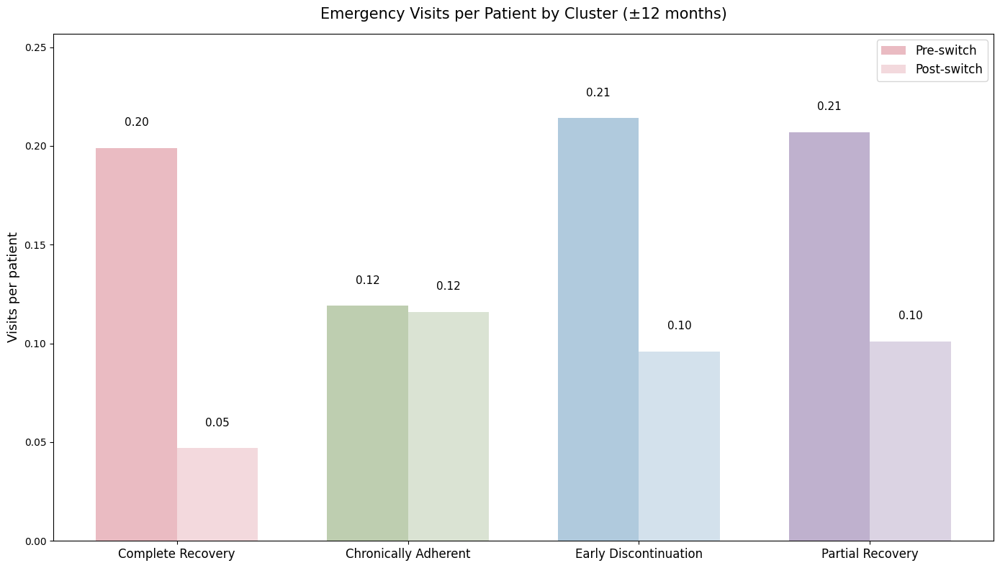

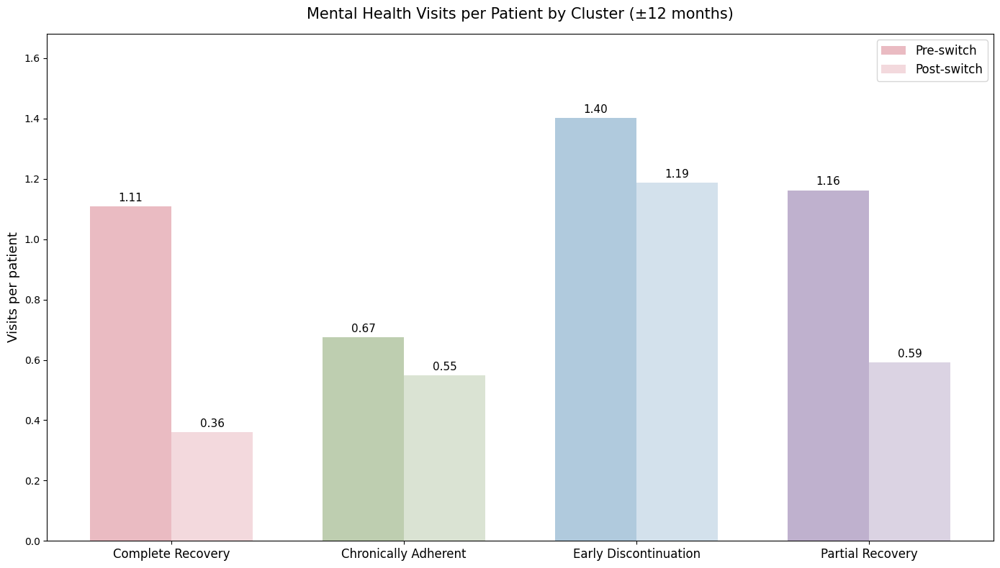

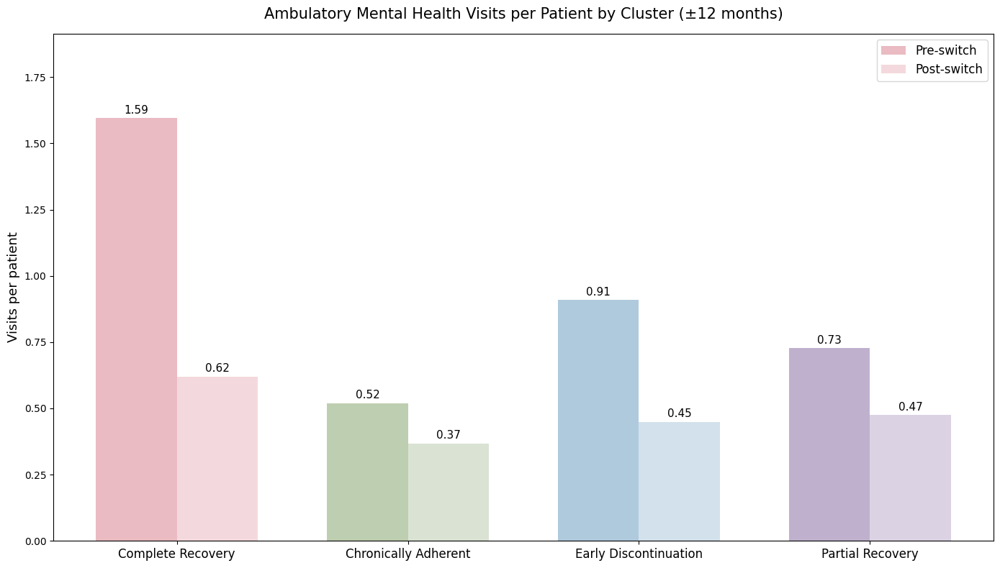

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

custom_k4 = ['#E8B4BC', '#B7C9A8', '#A8C5DA', '#B8A9C9']
cluster_labels = {0: 'Complete Recovery', 1: 'Chronically Adherent', 2: 'Early Discontinuation', 3: 'Partial Recovery'}

def plot_visits(df, name, cluster_sizes, title):
    counts = df.groupby(['cluster_k4', 'period']).size().unstack().fillna(0)
    counts_normalized = counts.div(cluster_sizes, axis=0).round(3)
    
    x = np.arange(4)
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(14, 8))
    
    bars_pre = ax.bar(x - width/2, counts_normalized['pre'], width, 
                      label='Pre-switch', color=[custom_k4[i] for i in range(4)], alpha=0.9)
    bars_post = ax.bar(x + width/2, counts_normalized['post'], width,
                       label='Post-switch', color=[custom_k4[i] for i in range(4)], alpha=0.5)
    
    # Add value labels on bars
    for bar in bars_pre:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=11)
    for bar in bars_post:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=11)
    
    ax.set_xticks(x)
    ax.set_xticklabels([cluster_labels[i] for i in range(4)], fontsize=12)
    ax.set_ylabel('Visits per patient', fontsize=13)
    ax.set_title(title, fontsize=15, pad=15)
    ax.legend(fontsize=12)
    ax.set_ylim(0, counts_normalized.values.max() * 1.2)
    
    plt.tight_layout()
    plt.savefig(rf'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\{name}_visits.png', 
                dpi=300, bbox_inches='tight')
    plt.show()

plot_visits(df_urg_cohort, 'URG', cluster_sizes, 'Emergency Visits per Patient by Cluster (±12 months)')
plot_visits(df_smh_cohort, 'SMH', cluster_sizes, 'Mental Health Visits per Patient by Cluster (±12 months)')
plot_visits(df_sma_cohort, 'SMA', cluster_sizes, 'Ambulatory Mental Health Visits per Patient by Cluster (±12 months)')

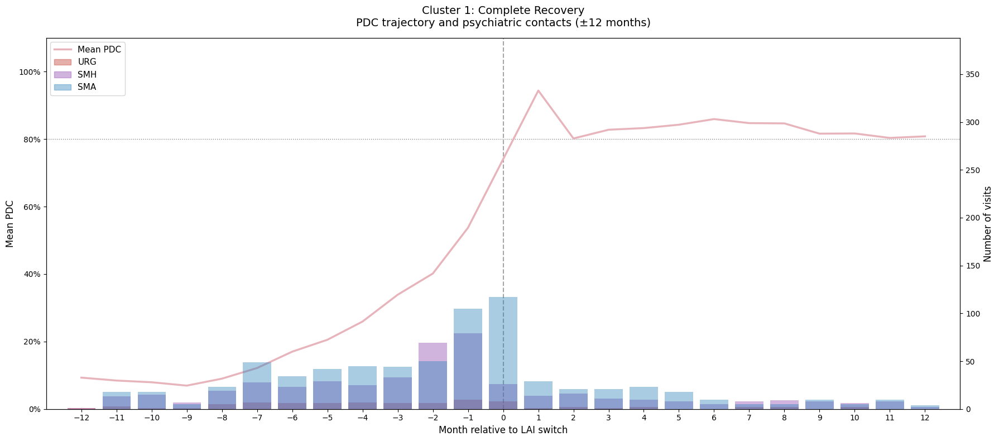

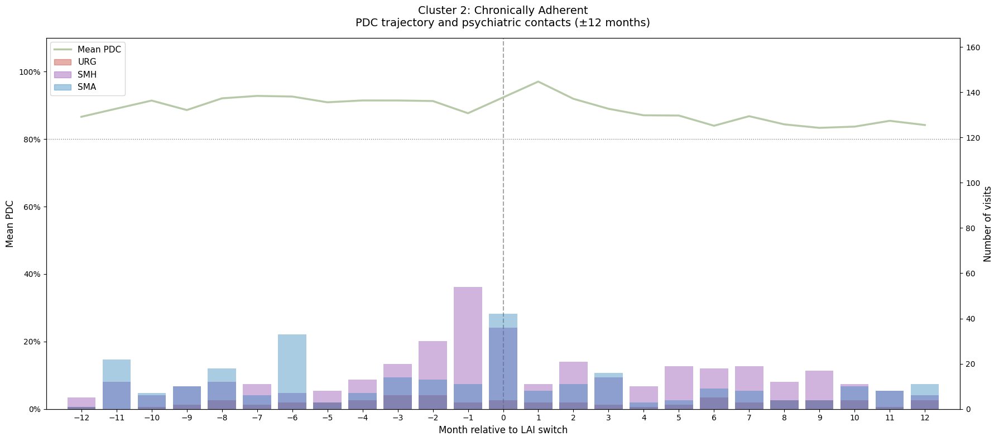

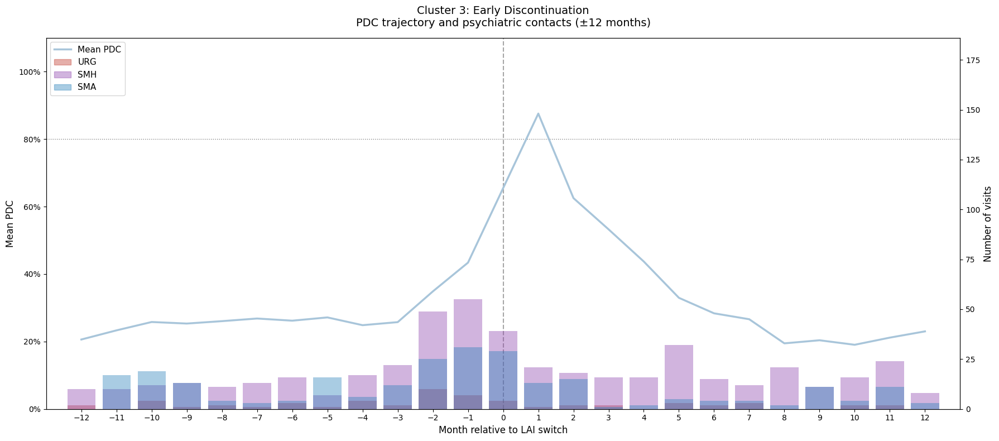

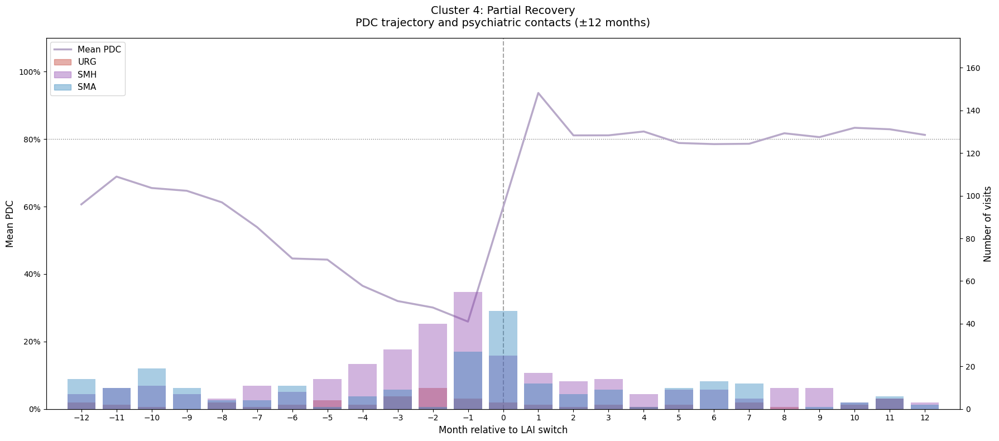

In [48]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np

custom_k4 = ['#E8B4BC', '#B7C9A8', '#A8C5DA', '#B8A9C9']
cluster_labels = {0: 'Complete Recovery', 1: 'Chronically Adherent', 2: 'Early Discontinuation', 3: 'Partial Recovery'}
visit_colors = {'URG': '#C0392B', 'SMH': '#8E44AD', 'SMA': '#2980B9'}

cols = [f'Month_{i}' for i in range(-12, 0)] + [f'Month_{i}' for i in range(1, 13)]
months = list(range(-12, 0)) + list(range(1, 13))

# Add month relative to switch for each visit table
for df, name in [(df_urg_cohort, 'URG'), (df_smh_cohort, 'SMH'), (df_sma_cohort, 'SMA')]:
    df['visit_month'] = (df['days_to_switch'] / 30.44).round().astype(int)
    df['visit_type'] = name

# Combine all visits
df_visits_all = pd.concat([
    df_urg_cohort[['idCas', 'cluster_k4', 'visit_month', 'visit_type']],
    df_smh_cohort[['idCas', 'cluster_k4', 'visit_month', 'visit_type']],
    df_sma_cohort[['idCas', 'cluster_k4', 'visit_month', 'visit_type']]
])

for cluster_id in range(4):
    fig, ax1 = plt.subplots(figsize=(18, 8))
    ax2 = ax1.twinx()
    
    # PDC trajectory
    cluster_data = pdc_switchers_csv[pdc_switchers_csv['cluster_k4'] == cluster_id]
    cluster_mean = cluster_data[cols].mean().values
    ax1.plot(months, cluster_mean, color=custom_k4[cluster_id], linewidth=2.5, label='Mean PDC', zorder=3)
    ax1.axvline(x=0, color='grey', linestyle='--', alpha=0.7)
    ax1.axhline(y=0.80, color='black', linestyle=':', linewidth=1, alpha=0.5)
    ax1.set_ylim(0, 1.1)
    ax1.set_ylabel('Mean PDC', fontsize=12)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    
    # Visit dots stacked per month
    cluster_visits = df_visits_all[df_visits_all['cluster_k4'] == cluster_id]
    
    for visit_type, color in visit_colors.items():
        type_visits = cluster_visits[cluster_visits['visit_type'] == visit_type]
        month_counts = type_visits.groupby('visit_month').size().reset_index(name='count')
        ax2.bar(month_counts['visit_month'], month_counts['count'], 
                color=color, alpha=0.4, width=0.8, label=visit_type)
    
    ax2.set_ylabel('Number of visits', fontsize=12)
    ax2.set_ylim(0, cluster_visits.groupby('visit_month').size().max() * 2)
    
    # Legends
    pdc_line = mlines.Line2D([], [], color=custom_k4[cluster_id], linewidth=2.5, label='Mean PDC')
    urg_patch = plt.Rectangle((0,0), 1, 1, color=visit_colors['URG'], alpha=0.4, label='URG')
    smh_patch = plt.Rectangle((0,0), 1, 1, color=visit_colors['SMH'], alpha=0.4, label='SMH')
    sma_patch = plt.Rectangle((0,0), 1, 1, color=visit_colors['SMA'], alpha=0.4, label='SMA')
    ax1.legend(handles=[pdc_line, urg_patch, smh_patch, sma_patch], fontsize=11, loc='upper left')
    
    ax1.set_xlabel('Month relative to LAI switch', fontsize=12)
    ax1.set_title(f'Cluster {cluster_id + 1}: {cluster_labels[cluster_id]}\nPDC trajectory and psychiatric contacts (±12 months)', 
                  fontsize=14, pad=15)
    ax1.set_xticks(range(-12, 13))
    ax1.set_xlim(-13, 13)
    
    plt.tight_layout()
    plt.savefig(rf'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\cluster_{cluster_id}_trajectory_visits.png', 
                dpi=300, bbox_inches='tight')
    plt.show()

In [49]:
print("URG primary diagnoses:")
print(df_urg_cohort['desc_dx_1'].value_counts().head(20))

print("\nSMH primary diagnoses:")
print(df_smh_cohort['desc_dx_1'].value_counts().head(20))

print("\nSMA primary diagnoses:")
print(df_sma_cohort['diag_1'].value_counts().head(20))

URG primary diagnoses:
desc_dx_1
Trastorn mental no psicòtic inepecificat                        69
Psicosi inespecificada; psicosi atípica; psicosi NOS            43
Esquizofrènia tipus paranoide inespecificada                    15
Esquizofrènia tipus paranoide crònica                           13
Esquizofrènia tipus paranoide crònica a/exacerbació aguda       11
Esquizofrènia tipus inespecificat, inespecificada               11
Trastorn esquizoafectiu inespecificat                           11
Trastorn esquizoafectiu crònic amb exacerbació aguda             8
Esquizofrènia inespecificada crònica amb exacerbació aguda       7
Altr.símptomes/síndromes especials nsp,no clasif.altre lloc      7
Trastorn delirant; Malaltia de Sander, Delusions sistematitz     5
Estat ansietat, inespecificat.; ansietat: neurosi, reacció       5
Trastorn bipolar I, tipus maníac inesp                           3
Estats d'ansietat                                                3
Idees de suïcidi             

In [50]:
# URG - check dx_1 and dx_2
print("URG - psychiatric in dx_1 or dx_2:")
psychiatric_keywords = ['squizofrèn', 'psicosi', 'esquizo', 'trastorn mental', 'trastorn esquizo', 
                        'trastorn bipolar', 'trastorn delirant', 'psicòtic']

def is_psychiatric(text):
    if pd.isna(text):
        return False
    return any(kw.lower() in text.lower() for kw in psychiatric_keywords)

df_urg_cohort['psych_dx1'] = df_urg_cohort['desc_dx_1'].apply(is_psychiatric)
df_urg_cohort['psych_dx2'] = df_urg_cohort['desc_dx_2'].apply(is_psychiatric)
df_urg_cohort['psych_any'] = df_urg_cohort['psych_dx1'] | df_urg_cohort['psych_dx2']

print(f"URG psychiatric in dx1: {df_urg_cohort['psych_dx1'].sum()} / {len(df_urg_cohort)} ({df_urg_cohort['psych_dx1'].mean()*100:.1f}%)")
print(f"URG psychiatric in dx1 or dx2: {df_urg_cohort['psych_any'].sum()} / {len(df_urg_cohort)} ({df_urg_cohort['psych_any'].mean()*100:.1f}%)")

df_smh_cohort['psych_dx1'] = df_smh_cohort['desc_dx_1'].apply(is_psychiatric)
df_smh_cohort['psych_dx2'] = df_smh_cohort['desc_dx_2'].apply(is_psychiatric)
df_smh_cohort['psych_any'] = df_smh_cohort['psych_dx1'] | df_smh_cohort['psych_dx2']

print(f"\nSMH psychiatric in dx1: {df_smh_cohort['psych_dx1'].sum()} / {len(df_smh_cohort)} ({df_smh_cohort['psych_dx1'].mean()*100:.1f}%)")
print(f"SMH psychiatric in dx1 or dx2: {df_smh_cohort['psych_any'].sum()} / {len(df_smh_cohort)} ({df_smh_cohort['psych_any'].mean()*100:.1f}%)")

URG - psychiatric in dx_1 or dx_2:
URG psychiatric in dx1: 221 / 273 (81.0%)
URG psychiatric in dx1 or dx2: 229 / 273 (83.9%)

SMH psychiatric in dx1: 1493 / 1693 (88.2%)
SMH psychiatric in dx1 or dx2: 1522 / 1693 (89.9%)


In [51]:
# SMA uses ICD-9 codes — psychiatric codes start with 29x, 30x, 31x
psychiatric_icd9_prefixes = ('29', '30', '31')

def is_psychiatric_icd9(code):
    if pd.isna(code):
        return False
    return str(code).startswith(psychiatric_icd9_prefixes)

df_sma_cohort['psych_dx1'] = df_sma_cohort['diag_1'].apply(is_psychiatric_icd9)
df_sma_cohort['psych_dx2'] = df_sma_cohort['diag_2'].apply(is_psychiatric_icd9)
df_sma_cohort['psych_any'] = df_sma_cohort['psych_dx1'] | df_sma_cohort['psych_dx2']

print(f"SMA psychiatric in dx1: {df_sma_cohort['psych_dx1'].sum()} / {len(df_sma_cohort)} ({df_sma_cohort['psych_dx1'].mean()*100:.1f}%)")
print(f"SMA psychiatric in dx1 or dx2: {df_sma_cohort['psych_any'].sum()} / {len(df_sma_cohort)} ({df_sma_cohort['psych_any'].mean()*100:.1f}%)")

SMA psychiatric in dx1: 1453 / 1486 (97.8%)
SMA psychiatric in dx1 or dx2: 1458 / 1486 (98.1%)


## Smoking status vs adh

In [52]:
df_socio = pd.read_csv(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\csv merged\cohort_schizophrenia_sociodemografica.csv')

switchers_socio = df_socio[df_socio['idCas'].isin(switchers_1517)].copy()

print(f"Switchers with sociodemographic data: {len(switchers_socio)}")
print(f"\nSmoking data available:")
print(switchers_socio[['never_smoker', 'current_smoker', 'ex_smoker', 'VAL_change']].notna().sum())
print(f"\nVAL_change distribution:")
print(switchers_socio['VAL_change'].value_counts(dropna=False))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\laiar\\Desktop\\Classe IDIBAPS\\data_sintetica\\Data-sintetica\\Data-sintetica\\src\\csv merged\\cohort_schizophrenia_sociodemografica.csv'

C:\Users\laiar\AppData\Local\Temp\ipykernel_9952\3336302639.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(val_change.index, rotation=20, ha='right')


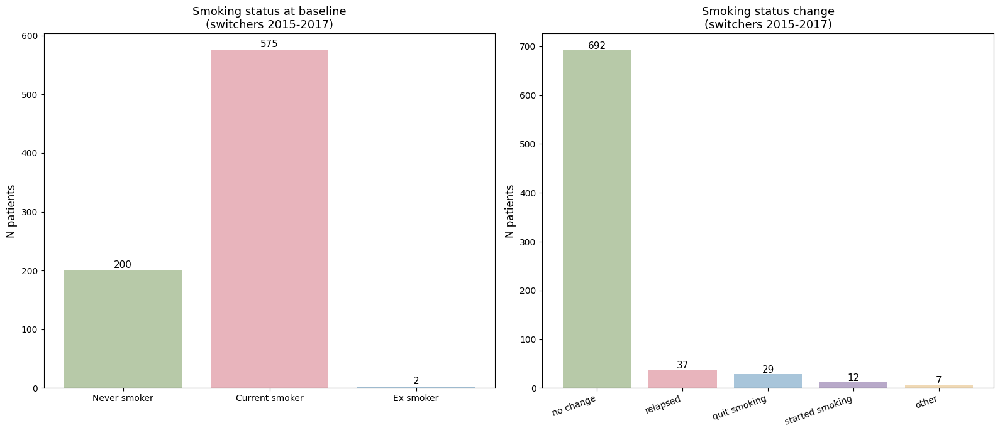

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: Smoking status distribution
smoking_status = pd.DataFrame({
    'Never smoker': switchers_socio['never_smoker'].sum(),
    'Current smoker': switchers_socio['current_smoker'].sum(),
    'Ex smoker': switchers_socio['ex_smoker'].sum()
}, index=[0]).T

axes[0].bar(smoking_status.index, smoking_status[0], 
            color=['#B7C9A8', '#E8B4BC', '#A8C5DA'])
axes[0].set_title('Smoking status at baseline\n(switchers 2015-2017)', fontsize=13)
axes[0].set_ylabel('N patients', fontsize=12)
for i, v in enumerate(smoking_status[0]):
    axes[0].text(i, v + 5, str(int(v)), ha='center', fontsize=11)

# Plot 2: VAL_change distribution
val_change = switchers_socio['VAL_change'].value_counts().dropna()
colors = ['#B7C9A8', '#E8B4BC', '#A8C5DA', '#B8A9C9', '#F0D9B5']
axes[1].bar(val_change.index, val_change.values, color=colors[:len(val_change)])
axes[1].set_title('Smoking status change\n(switchers 2015-2017)', fontsize=13)
axes[1].set_ylabel('N patients', fontsize=12)
axes[1].set_xticklabels(val_change.index, rotation=20, ha='right')
for i, v in enumerate(val_change.values):
    axes[1].text(i, v + 3, str(v), ha='center', fontsize=11)

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\smoking_distribution.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [47]:
switchers_socio_clusters = switchers_socio.merge(
    pdc_switchers_csv[['idCas', 'cluster_k4']], on='idCas', how='left'
)

print(switchers_socio_clusters.groupby('cluster_k4')['current_smoker'].sum())
print(switchers_socio_clusters.groupby('cluster_k4')['VAL_change'].value_counts())

cluster_k4
0    184.0
1    193.0
2     84.0
3    114.0
Name: current_smoker, dtype: float64
cluster_k4  VAL_change     
0           no change          233
            quit smoking        12
            relapsed             6
            started smoking      2
            other                1
1           no change          210
            relapsed            16
            quit smoking        10
            started smoking      4
            other                1
2           no change          128
            relapsed             5
            quit smoking         3
            other                1
            started smoking      1
3           no change          121
            relapsed            10
            started smoking      5
            other                4
            quit smoking         4
Name: count, dtype: int64


In [48]:
switchers_socio_clusters = switchers_socio_clusters.merge(
    first_lai_dates, on='idCas', how='left'
)
switchers_socio_clusters['data_inici'] = pd.to_datetime(switchers_socio_clusters['data_inici'], utc=True).dt.tz_localize(None)
switchers_socio_clusters['first_lai_date'] = pd.to_datetime(switchers_socio_clusters['first_lai_date'])
switchers_socio_clusters['days_to_switch'] = (switchers_socio_clusters['data_inici'] - switchers_socio_clusters['first_lai_date']).dt.days
switchers_socio_clusters['month_to_switch'] = (switchers_socio_clusters['days_to_switch'] / 30.44).round().astype('Int64')

# Filter to ±12 months
smoking_events = switchers_socio_clusters[
    (switchers_socio_clusters['VAL_change'] != 'no change') &
    (switchers_socio_clusters['month_to_switch'].between(-12, 12))
]

print(smoking_events[['cluster_k4', 'VAL_change', 'month_to_switch']].value_counts().sort_index())

cluster_k4  VAL_change    month_to_switch
0           quit smoking  -2                 2
            relapsed      -1                 1
2           relapsed      -10                1
                          -5                 1
3           quit smoking  -10                1
Name: count, dtype: int64


In [54]:
# Better to show a table than a graph with so few events
from scipy import stats

# Merge clusters with sociodemographic data
table1 = switchers_socio_clusters.copy()
table1['cluster_k4'] = table1['cluster_k4'].map({
    0: 'LAI Improvers',
    1: 'Chronically Adherent', 
    2: 'Early Dropouts',
    3: 'Moderate Improvers'
})

# Define variables
results = []

# Sex
for cluster in table1['cluster_k4'].unique():
    subset = table1[table1['cluster_k4'] == cluster]
    n = len(subset)
    n_female = subset['SEXE1'].sum()
    results.append({'cluster': cluster, 'variable': 'Female, n (%)', 
                    'value': f"{int(n_female)} ({n_female/n*100:.1f}%)"})

# Age
for cluster in table1['cluster_k4'].unique():
    subset = table1[table1['cluster_k4'] == cluster]
    results.append({'cluster': cluster, 'variable': 'Age group (most common)', 
                    'value': subset['EDAT_rang'].mode()[0]})

# Smoking
for cluster in table1['cluster_k4'].unique():
    subset = table1[table1['cluster_k4'] == cluster]
    n = len(subset)
    n_current = subset['current_smoker'].sum()
    n_never = subset['never_smoker'].sum()
    n_ex = subset['ex_smoker'].sum()
    results.append({'cluster': cluster, 'variable': 'Current smoker, n (%)', 
                    'value': f"{int(n_current)} ({n_current/n*100:.1f}%)"})
    results.append({'cluster': cluster, 'variable': 'Never smoker, n (%)', 
                    'value': f"{int(n_never)} ({n_never/n*100:.1f}%)"})
    results.append({'cluster': cluster, 'variable': 'Ex smoker, n (%)', 
                    'value': f"{int(n_ex)} ({n_ex/n*100:.1f}%)"})

# BMI
for cluster in table1['cluster_k4'].unique():
    subset = table1[table1['cluster_k4'] == cluster]
    bmi = subset['BMI_last'].dropna()
    if len(bmi) > 0:
        results.append({'cluster': cluster, 'variable': 'BMI last, mean (SD)', 
                        'value': f"{bmi.mean():.1f} ({bmi.std():.1f})"})

# NIVSOC
for cluster in table1['cluster_k4'].unique():
    subset = table1[table1['cluster_k4'] == cluster]
    results.append({'cluster': cluster, 'variable': 'Socioeconomic level (most common)', 
                    'value': subset['NIVSOC'].mode()[0] if len(subset['NIVSOC'].dropna()) > 0 else 'N/A'})

# Pivot to wide format
df_table1 = pd.DataFrame(results).pivot(index='variable', columns='cluster', values='value')
df_table1 = df_table1[['LAI Improvers', 'Chronically Adherent', 'Early Dropouts', 'Moderate Improvers']]

print(df_table1.to_string())
print(f"\n* Smoking data available for {int(table1['current_smoker'].notna().sum())} / {len(table1)} patients ({table1['current_smoker'].notna().mean()*100:.1f}%)")

NameError: name 'switchers_socio_clusters' is not defined

## Toxicity calculation

In [55]:
print(df_23_dispensats.columns.tolist())
print(df_25_mhda.columns.tolist())

['id', 'idCas', 'Any_Mes', 'ID_HIS_Subgrup_7_ATC', 'DES_HIS_Subgrup_7_ATC', 'ID_HIS_Producte', 'DES_HIS_Producte', 'HIS_Quantitat_PA_Espec', 'ID_HIS_Unitat_Mesura_PA_Espec', 'DES_HIS_Unitat_Mesura_PA_Espec', 'HIS_Unitats_Productes', 'ID_HIS_Forma_Farmaceutica', 'DES_HIS_Forma_Farmaceutica', 'ID_HIS_Via_Administracio_Producte', 'DES_HIS_Via_Administracio_Producte', 'Nombre_Receptes_Dispensades', 'Nombre_DDD_Receptes_Dispensades', 'Import_Integre_Dispensades', 'Import_Liquid_Dispensat', 'Nombre_Envasos_Dispensats']
['id', 'idCas', 'Any_Mes', '(HIS) Subgrup 7 (ATC)', '(HIS) Subgrup 7 (ATC) Desc', '(HIS) Forma Farmacèutica', '(HIS) Forma Farmacèutica Desc', '(HIS) Producte', '(HIS) Producte Desc', '(HIS) Via de distribució', 'Concepte Facturació', 'Concepte Facturació Desc', 'Import activitat MHDA']


In [56]:
def anymes_to_date(anymes):
    anymes = str(int(anymes))
    return pd.Timestamp(year=int(anymes[:4]), month=int(anymes[4:]), day=15)

df_23_dispensats['dispensing_date'] = df_23_dispensats['Any_Mes'].apply(anymes_to_date)
df_25_mhda['dispensing_date'] = df_25_mhda['Any_Mes'].apply(anymes_to_date)

# Also apply classification
df_23_dispensats['formulation_type'] = df_23_dispensats['DES_HIS_Producte'].apply(classify_product)
df_25_mhda['formulation_type'] = df_25_mhda['(HIS) Producte Desc'].apply(classify_product)

In [58]:
# Combine dispensing tables for switchers - both tables
disp_23 = df_23_dispensats[df_23_dispensats['idCas'].isin(switchers_1517)][['idCas', 'dispensing_date', 'DES_HIS_Producte', 'formulation_type']].rename(columns={'DES_HIS_Producte': 'product'})
disp_25 = df_25_mhda[df_25_mhda['idCas'].isin(switchers_1517)][['idCas', 'dispensing_date', '(HIS) Producte Desc', 'formulation_type']].rename(columns={'(HIS) Producte Desc': 'product'})

disp_combined = pd.concat([disp_23, disp_25])
disp_combined = disp_combined[disp_combined['formulation_type'].isin(['ORAL', 'LAI'])]
disp_combined = disp_combined.sort_values(['idCas', 'dispensing_date']).reset_index(drop=True)

# Detect changes
disp_combined['prev_product'] = disp_combined.groupby('idCas')['product'].shift(1)
disp_combined['prev_type'] = disp_combined.groupby('idCas')['formulation_type'].shift(1)
disp_combined['is_change'] = (
    disp_combined['product'] != disp_combined['prev_product']
) & disp_combined['prev_product'].notna()

med_changes = disp_combined[disp_combined['is_change']].copy()
med_changes['change_type'] = med_changes['prev_type'] + '->' + med_changes['formulation_type']

print(med_changes['change_type'].value_counts())
print(f"\nTotal medication changes: {len(med_changes)}")
print(f"Patients with at least one change: {med_changes['idCas'].nunique()}")

change_type
ORAL->ORAL    34718
ORAL->LAI     14295
LAI->ORAL     13774
LAI->LAI       4251
Name: count, dtype: int64

Total medication changes: 67038
Patients with at least one change: 1025


In [59]:
# Range: 60 days after meds changes
# Merge med_changes with switch dates
med_changes = med_changes.merge(first_lai_dates, on='idCas', how='left')
med_changes = med_changes.merge(pdc_switchers_csv[['idCas', 'cluster_k4']], on='idCas', how='left')

# Filter to post-switch window only
med_changes['days_to_switch'] = (med_changes['dispensing_date'] - med_changes['first_lai_date']).dt.days
med_changes_post = med_changes[(med_changes['days_to_switch'] >= 0) & (med_changes['days_to_switch'] <= 365)]

print(f"Medication changes in post-switch window: {len(med_changes_post)}")
print(med_changes_post['change_type'].value_counts())

# For each change, check if there's a visit within 60 days
all_visits = pd.concat([
    df_urg_cohort[['idCas', 'dat_ini']].assign(visit_type='URG'),
    df_smh_cohort[['idCas', 'dat_ini']].assign(visit_type='SMH'),
    df_sma_cohort[['idCas', 'Data inici assistència']].rename(columns={'Data inici assistència': 'dat_ini'}).assign(visit_type='SMA')
])
all_visits['dat_ini'] = pd.to_datetime(all_visits['dat_ini'], errors='coerce')

# Check for visits within 60 days after each change
records = []
for _, change in med_changes_post.iterrows():
    window_end = change['dispensing_date'] + pd.Timedelta(days=60)
    visits = all_visits[
        (all_visits['idCas'] == change['idCas']) &
        (all_visits['dat_ini'] >= change['dispensing_date']) &
        (all_visits['dat_ini'] <= window_end)
    ]
    records.append({
        'idCas': change['idCas'],
        'change_date': change['dispensing_date'],
        'change_type': change['change_type'],
        'cluster_k4': change['cluster_k4'],
        'n_visits_60d': len(visits),
        'had_visit': len(visits) > 0
    })

toxicity_df = pd.DataFrame(records)
print(f"\nChanges followed by a visit within 60 days: {toxicity_df['had_visit'].sum()} / {len(toxicity_df)} ({toxicity_df['had_visit'].mean()*100:.1f}%)")
print(toxicity_df.groupby(['cluster_k4', 'change_type'])['had_visit'].mean().round(3))

Medication changes in post-switch window: 16805
change_type
ORAL->LAI     5990
LAI->ORAL     5363
ORAL->ORAL    3448
LAI->LAI      2004
Name: count, dtype: int64

Changes followed by a visit within 60 days: 1900 / 16805 (11.3%)
cluster_k4  change_type
0           LAI->LAI       0.111
            LAI->ORAL      0.117
            ORAL->LAI      0.117
            ORAL->ORAL     0.114
1           LAI->LAI       0.114
            LAI->ORAL      0.080
            ORAL->LAI      0.084
            ORAL->ORAL     0.128
2           LAI->LAI       0.172
            LAI->ORAL      0.190
            ORAL->LAI      0.204
            ORAL->ORAL     0.195
3           LAI->LAI       0.165
            LAI->ORAL      0.108
            ORAL->LAI      0.118
            ORAL->ORAL     0.098
Name: had_visit, dtype: float64


**Overall**: 11.3% of medication changes were followed by a visit within 60 days.

**By cluster**:

- **Cluster 2 (Early Dropouts)** has the highest rate across all change types (~17-20%), consistent with their poor adherence and instability
- **Cluster 1 (Chronically Adherent)** has the lowest rates (~8-13%), stable patients tolerate changes better
- **Cluster 0 (LAI Improvers) and Cluster 3 (Moderate Improvers)** are in the middle (~11-17%)

**By change type in Cluster 2**:

- ORAL→LAI: 20.4% — highest of all, suggesting Early Dropouts struggle most when initiating LAI
- LAI→ORAL: 19.0% — also high, suggesting switching back to oral also causes instability

C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\3362143361.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(rates.index, rotation=25, ha='right', fontsize=12)
C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\3362143361.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(rates.index, rotation=25, ha='right', fontsize=12)
C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\3362143361.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(rates.index, rotation=25, ha='right', fontsize=12)
C:\Users\laiar\AppData\Local\Temp\ipykernel_17496\3362143361.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


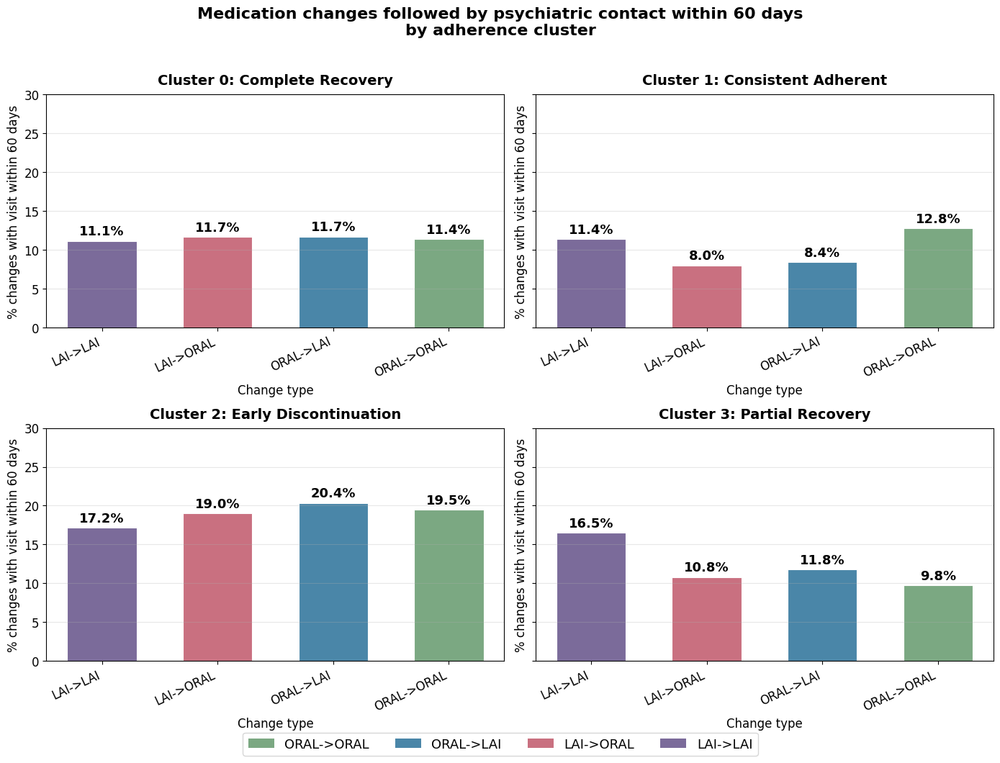

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes = axes.flatten()

cluster_labels = {0: 'Complete Recovery', 1: 'Consistent Adherent', 2: 'Early Discontinuation', 3: 'Partial Recovery'}
change_colors = {
    'ORAL->ORAL': '#7BA882',
    'ORAL->LAI':  '#4A86A8',
    'LAI->ORAL':  '#C97080',
    'LAI->LAI':   '#7B6B9A'
}

for cluster_id in range(4):
    ax = axes[cluster_id]
    cluster_data = toxicity_df[toxicity_df['cluster_k4'] == cluster_id]
    rates = cluster_data.groupby('change_type')['had_visit'].mean() * 100

    bars = ax.bar(rates.index, rates.values,
                  color=[change_colors[ct] for ct in rates.index],
                  width=0.6, edgecolor='white', linewidth=0.8)

    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
                f'{bar.get_height():.1f}%',
                ha='center', va='bottom', fontsize=13, fontweight='bold')

    ax.set_title(f'Cluster {cluster_id}: {cluster_labels[cluster_id]}',
                 fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel('Change type', fontsize=12)
    ax.set_ylabel('% changes with visit within 60 days', fontsize=12)
    ax.set_xticklabels(rates.index, rotation=25, ha='right', fontsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 30)
    ax.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=change_colors[ct], label=ct) for ct in change_colors]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=13,
           bbox_to_anchor=(0.5, -0.03))

plt.suptitle('Medication changes followed by psychiatric contact within 60 days\nby adherence cluster',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\toxicity_by_cluster.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [62]:
# Use ALL med_changes (not just post-switch)
med_changes_all = med_changes.copy()  # already has all changes

records = []
for _, change in med_changes_all.iterrows():
    window_end = change['dispensing_date'] + pd.Timedelta(days=60)
    visits = all_visits[
        (all_visits['idCas'] == change['idCas']) &
        (all_visits['dat_ini'] >= change['dispensing_date']) &
        (all_visits['dat_ini'] <= window_end)
    ]
    records.append({
        'idCas': change['idCas'],
        'change_date': change['dispensing_date'],
        'change_type': change['change_type'],
        'cluster_k4': change['cluster_k4'],
        'n_visits_60d': len(visits),
        'had_visit': len(visits) > 0
    })

toxicity_df_all = pd.DataFrame(records)
print(f"Total changes: {len(toxicity_df_all)}")
print(f"With visit within 60 days: {toxicity_df_all['had_visit'].sum()} ({toxicity_df_all['had_visit'].mean()*100:.1f}%)")

Total changes: 67038
With visit within 60 days: 2988 (4.5%)


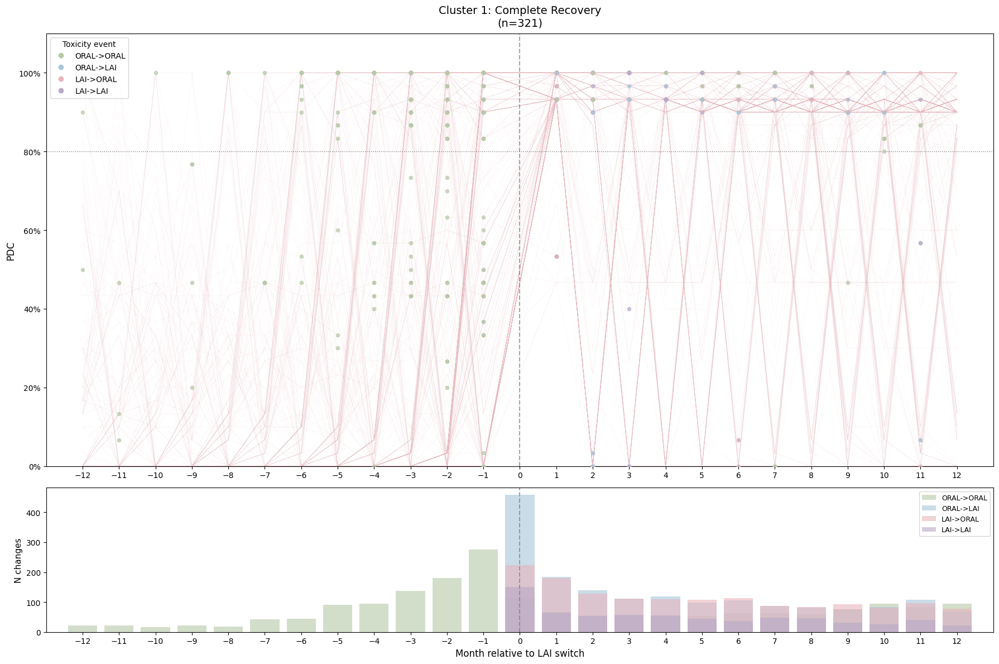

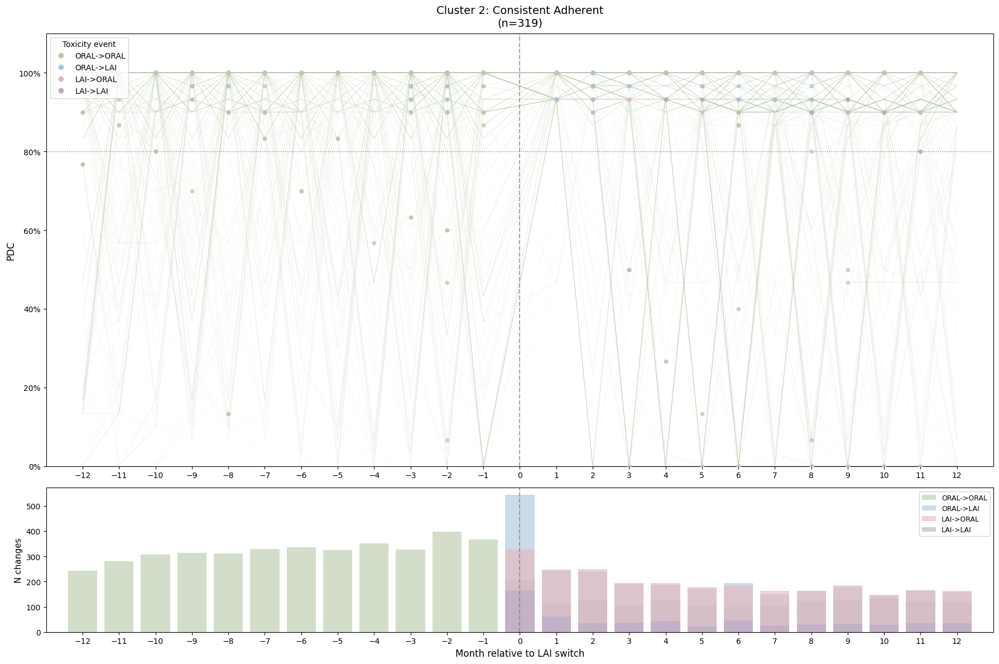

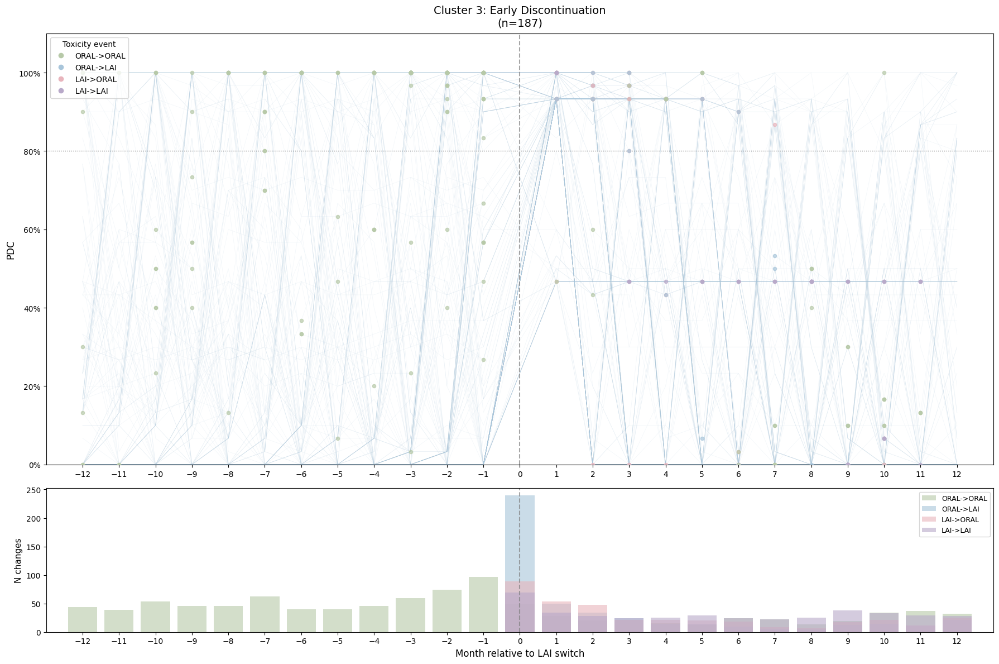

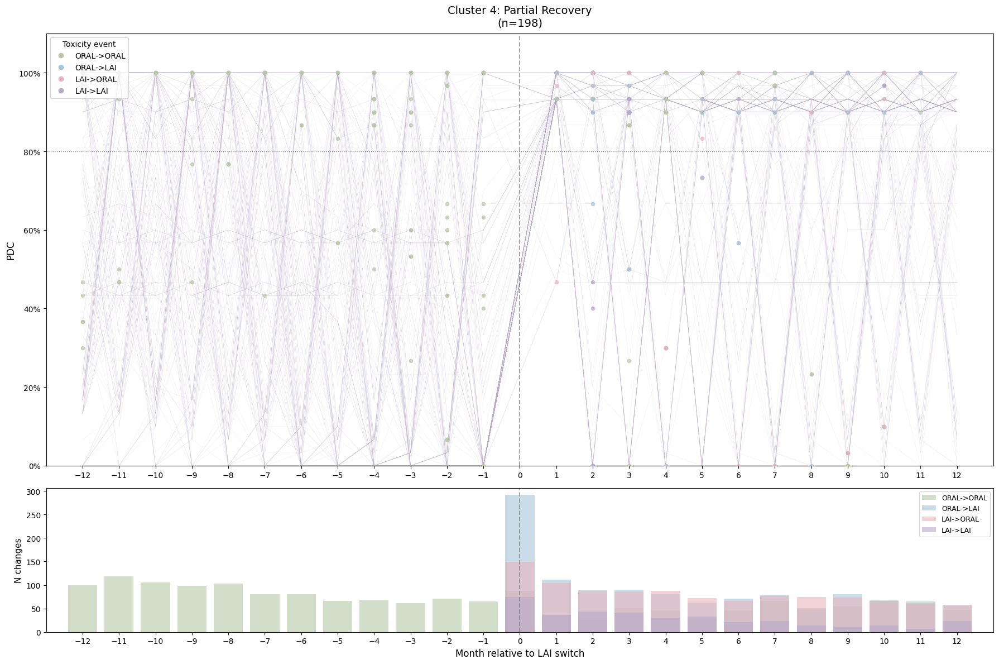

In [64]:
# Toxicity events per adherence lines per pantient - Medication changes followed by visits within 60 days, split by cluster and change type
# Prepare toxicity events with month relative to switch
toxicity_events = toxicity_df_all[toxicity_df_all['had_visit'] == True].copy()
toxicity_events = toxicity_events.merge(first_lai_dates, on='idCas', how='left')
toxicity_events['days_to_switch'] = (toxicity_events['change_date'] - toxicity_events['first_lai_date']).dt.days
toxicity_events['month_to_switch'] = (toxicity_events['days_to_switch'] / 30.44).round().astype(int)
toxicity_events = toxicity_events[toxicity_events['month_to_switch'].between(-12, 12)]

change_colors = {'ORAL->ORAL': '#B7C9A8', 'ORAL->LAI': '#A8C5DA', 
                 'LAI->ORAL': '#E8B4BC', 'LAI->LAI': '#B8A9C9'}

cols_pre = [f'Month_{i}' for i in range(-12, 0)]
cols_post = [f'Month_{i}' for i in range(1, 13)]
cols = cols_pre + cols_post
months = list(range(-12, 0)) + list(range(1, 13))

for cluster_id in range(4):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 12), 
                                    gridspec_kw={'height_ratios': [3, 1]})
    
    cluster_data = pdc_switchers_csv[pdc_switchers_csv['cluster_k4'] == cluster_id]
    cluster_toxicity = toxicity_events[toxicity_events['cluster_k4'] == cluster_id]
    
    # Top panel - individual trajectories with toxicity dots
    for pid in cluster_data['idCas']:
        patient_pdc = cluster_data[cluster_data['idCas'] == pid][cols].values[0]
        ax1.plot(months, patient_pdc, color=custom_k4[cluster_id], 
                alpha=0.15, linewidth=0.5)
        
        # Toxicity dots for this patient
        patient_tox = cluster_toxicity[cluster_toxicity['idCas'] == pid]
        for _, tox in patient_tox.iterrows():
            month = tox['month_to_switch']
            if month in range(-12, 0):
                col = f'Month_{month}'
            elif month in range(1, 13):
                col = f'Month_{month}'
            else:
                continue
            if col in cols:
                pdc_val = cluster_data[cluster_data['idCas'] == pid][col].values[0]
                ax1.scatter(month, pdc_val, 
                           color=change_colors[tox['change_type']], 
                           s=20, zorder=5, alpha=0.7)
    
    ax1.axvline(x=0, color='grey', linestyle='--', alpha=0.7)
    ax1.axhline(y=0.80, color='black', linestyle=':', linewidth=1, alpha=0.5)
    ax1.set_ylim(0, 1.1)
    ax1.set_ylabel('PDC', fontsize=12)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax1.set_xticks(range(-12, 13))
    ax1.set_xlim(-13, 13)
    ax1.set_title(f'Cluster {cluster_id + 1}: {cluster_labels[cluster_id]}\n(n={len(cluster_data)})', 
                  fontsize=14, pad=10)
    
    # Legend for dots
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', 
                               markerfacecolor=change_colors[ct], markersize=8, label=ct) 
                       for ct in change_colors]
    ax1.legend(handles=legend_elements, fontsize=10, loc='upper left', title='Toxicity event')
    
    # Bottom panel - medication changes per month
    for change_type, color in change_colors.items():
        type_changes = toxicity_df_all[
            (toxicity_df_all['cluster_k4'] == cluster_id) & 
            (toxicity_df_all['change_type'] == change_type)
        ].merge(first_lai_dates, on='idCas', how='left')
        type_changes['days_to_switch'] = (type_changes['change_date'] - type_changes['first_lai_date']).dt.days
        type_changes['month'] = (type_changes['days_to_switch'] / 30.44).round().astype(int)
        type_changes = type_changes[type_changes['month'].between(-12, 12)]
        month_counts = type_changes.groupby('month').size()
        ax2.bar(month_counts.index, month_counts.values, color=color, alpha=0.6, 
                width=0.8, label=change_type)
    
    ax2.axvline(x=0, color='grey', linestyle='--', alpha=0.7)
    ax2.set_ylabel('N changes', fontsize=11)
    ax2.set_xlabel('Month relative to LAI switch', fontsize=12)
    ax2.set_xticks(range(-12, 13))
    ax2.set_xlim(-13, 13)
    ax2.legend(fontsize=9, loc='upper right')
    
    plt.tight_layout()
    plt.savefig(rf'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\cluster_{cluster_id}_full.png',
                dpi=300, bbox_inches='tight')
    plt.show()

In [65]:
print(toxicity_events[toxicity_events['cluster_k4'] == 0].shape)
print(toxicity_events[toxicity_events['cluster_k4'] == 0]['month_to_switch'].value_counts().sort_index())

(850, 9)
month_to_switch
-12      2
-11      3
-10      1
-9       4
-8       3
-7       6
-6      12
-5      29
-4      26
-3      46
-2      66
-1     104
 0     205
 1      89
 2      58
 3      43
 4      29
 5      24
 6      16
 7      26
 8      18
 9      20
 10     10
 11     10
Name: count, dtype: int64


In [66]:
print(toxicity_events.columns.tolist())
print(toxicity_events.head(2))

['idCas', 'change_date', 'change_type', 'cluster_k4', 'n_visits_60d', 'had_visit', 'first_lai_date', 'days_to_switch', 'month_to_switch']
      idCas change_date change_type  cluster_k4  n_visits_60d  had_visit  \
0  83951106  2015-09-15  ORAL->ORAL           3             1       True   
1  83951106  2015-10-15   ORAL->LAI           3             1       True   

  first_lai_date  days_to_switch  month_to_switch  
0     2015-10-15             -30               -1  
1     2015-10-15               0                0  


In [67]:
cluster_sizes = pdc_switchers_csv['cluster_k4'].value_counts().sort_index()
print(cluster_sizes)

cluster_k4
0    321
1    319
2    187
3    198
Name: count, dtype: int64


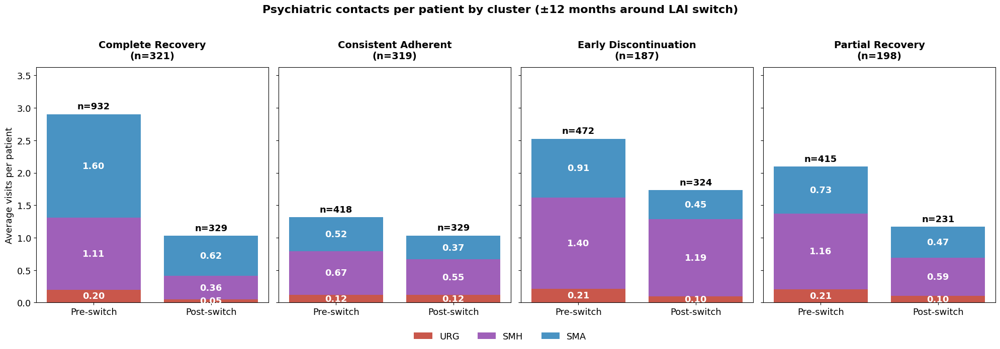

In [69]:
cluster_order = [0, 1, 2, 3]   # reorder here if you want it to match the poster

fig, axes = plt.subplots(1, 4, figsize=(20, 7), sharey=True)

global_max = 0
for i, cluster_id in enumerate(cluster_order):
    ax = axes[i]

    counts = {}
    for name, df in [('URG', df_urg_cohort), ('SMH', df_smh_cohort), ('SMA', df_sma_cohort)]:
        c = df[df['cluster_k4'] == cluster_id].groupby('period').size()
        counts[name] = c.reindex(['pre', 'post']).fillna(0) / cluster_sizes[cluster_id]

    df_plot = pd.DataFrame(counts).T

    bottom_pre = 0
    bottom_post = 0
    for visit_type, color in visit_colors.items():
        pre_val = df_plot.loc[visit_type, 'pre']
        post_val = df_plot.loc[visit_type, 'post']

        ax.bar('Pre-switch', pre_val, bottom=bottom_pre, color=color, alpha=0.85, label=visit_type)
        ax.bar('Post-switch', post_val, bottom=bottom_post, color=color, alpha=0.85)

        if pre_val > 0.02:
            ax.text(0, bottom_pre + pre_val/2, f'{pre_val:.2f}',
                    ha='center', va='center', fontsize=13, color='white', fontweight='bold')
        if post_val > 0.02:
            ax.text(1, bottom_post + post_val/2, f'{post_val:.2f}',
                    ha='center', va='center', fontsize=13, color='white', fontweight='bold')

        bottom_pre += pre_val
        bottom_post += post_val

    n_pre  = int(bottom_pre  * cluster_sizes[cluster_id])
    n_post = int(bottom_post * cluster_sizes[cluster_id])
    ax.text(0, bottom_pre  + 0.05, f'n={n_pre}',  ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax.text(1, bottom_post + 0.05, f'n={n_post}', ha='center', va='bottom', fontsize=13, fontweight='bold')

    ax.set_title(f'{cluster_labels[cluster_id]}\n(n={cluster_sizes[cluster_id]})',
                 fontsize=14, fontweight='bold', pad=12)
    ax.set_ylabel('Average visits per patient' if i == 0 else '', fontsize=13)
    ax.tick_params(axis='both', labelsize=13)

    global_max = max(global_max, bottom_pre, bottom_post)

# one shared y-limit (sharey=True links all panels)
axes[0].set_ylim(0, global_max * 1.25)

# single legend for the whole figure instead of one per panel
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=13, frameon=False)

plt.suptitle('Psychiatric contacts per patient by cluster (±12 months around LAI switch)',
             fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.07, 1, 0.95])   # leave room for legend and title
plt.show()

## U-MAP

In [70]:
# Clustring continuous PDC
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from sklearn.metrics import silhouette_score
import numpy as np

# Prepare data for tslearn (3D array: n_patients, n_timepoints, 1)
e_3d = embedding.reshape((embedding.shape[0], embedding.shape[1], 1))

# Test k=2 to 5 and compute silhouette scores
silhouette_scores = {}

for k in range(2, 6):
    model = TimeSeriesKMeans(n_clusters=k, metric="euclidean", random_state=42, n_jobs=-1)
    labels = model.fit_predict(e_3d)
    score = silhouette_score(embedding, labels)
    silhouette_scores[k] = score
    print(f"k={k}: silhouette={score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nBest k: {best_k}")

k=2: silhouette=0.5395
k=3: silhouette=0.5299
k=4: silhouette=0.5505
k=5: silhouette=0.5094

Best k: 4


Datos ruidosos --> clustering con U-MAP para maximizar el numero de clases

c:\Users\laiar\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


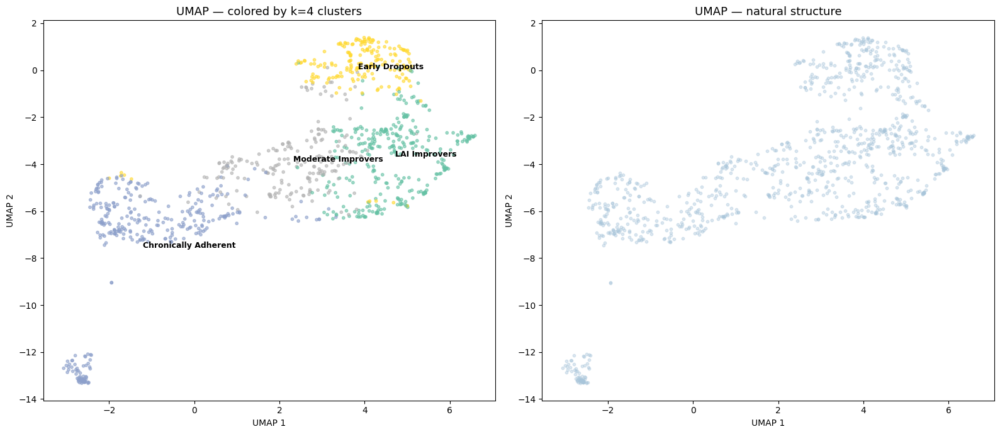

In [71]:
import umap

# Prepare data
X = pdc_switchers_csv[cols].values

# Fit UMAP
reducer = umap.UMAP(n_components=2, random_state=42)
embedding = reducer.fit_transform(X)

# Plot colored by k4 clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: colored by cluster_k4
scatter = axes[0].scatter(embedding[:, 0], embedding[:, 1], 
                          c=pdc_switchers_csv['cluster_k4'], 
                          cmap='Set2', alpha=0.6, s=10)
axes[0].set_title('UMAP — colored by k=4 clusters', fontsize=13)
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

# Add cluster labels
for cluster_id in range(4):
    mask = pdc_switchers_csv['cluster_k4'] == cluster_id
    cx = embedding[mask, 0].mean()
    cy = embedding[mask, 1].mean()
    axes[0].annotate(cluster_labels[cluster_id], (cx, cy), fontsize=9, fontweight='bold')

# Right: no color to see natural structure
axes[1].scatter(embedding[:, 0], embedding[:, 1], 
                color='#A8C5DA', alpha=0.4, s=10)
axes[1].set_title('UMAP — natural structure', fontsize=13)
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')

plt.tight_layout()
plt.savefig(r'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\umap_clusters.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [72]:
# Replace IQR with 95% confidence interval of the mean instead
from scipy import stats

mean_pdc = cluster_data[cols].mean().values
sem_pdc = cluster_data[cols].sem().values
ci95 = 1.96 * sem_pdc

ax1.fill_between(months, mean_pdc - ci95, mean_pdc + ci95, 
                 color=custom_k4[cluster_id], alpha=0.2, label='95% CI')
ax1.plot(months, mean_pdc, color=custom_k4[cluster_id], linewidth=2.5, label='Mean PDC')

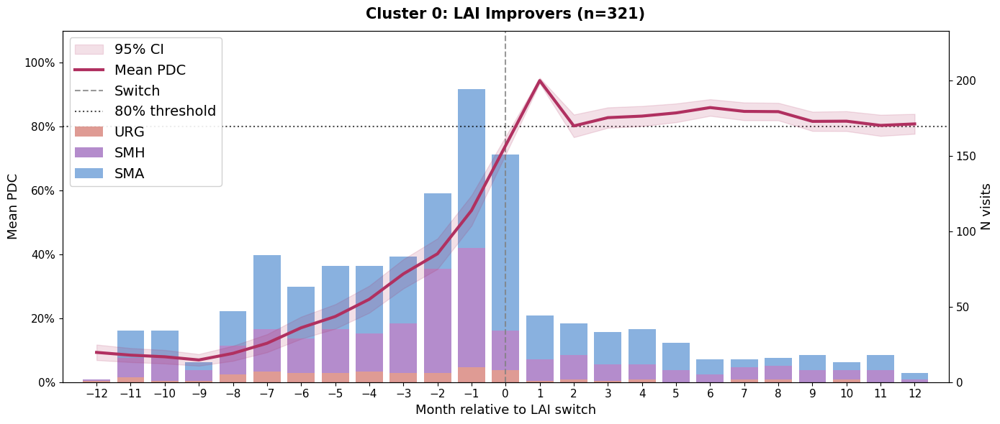

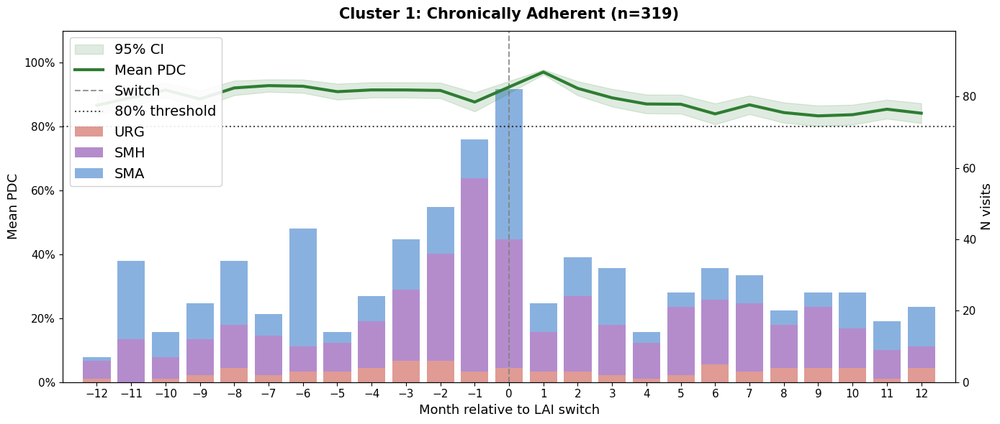

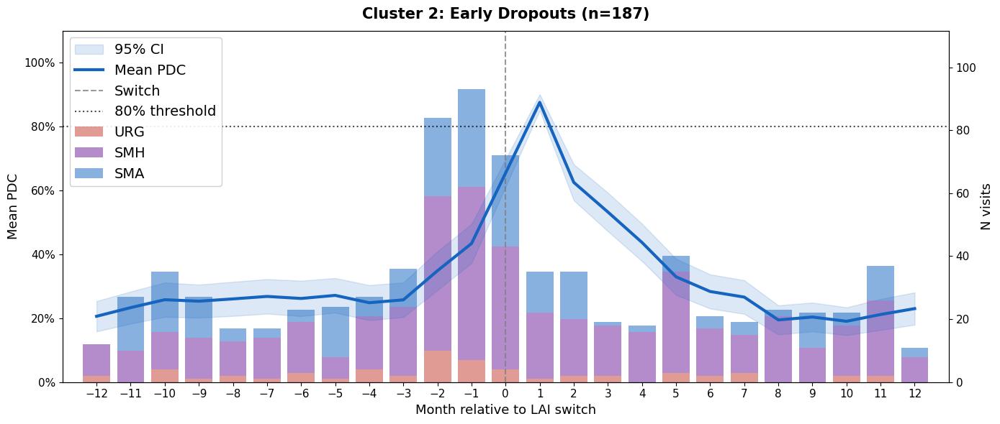

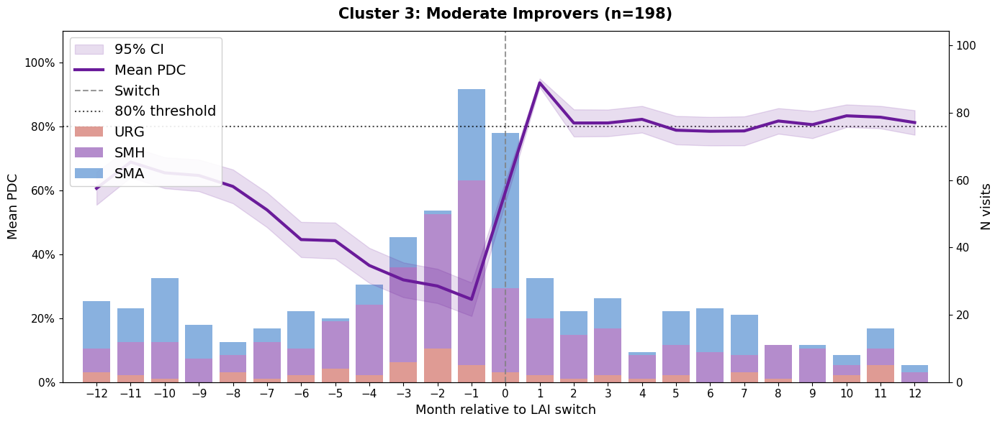

In [42]:
from scipy import stats
import numpy as np

custom_k4_dark = ['#B03060', '#2E7D32', '#1565C0', '#6A1B9A']
visit_colors_plot = {'URG': '#C0392B', 'SMH': '#6A1B9A', 'SMA': '#1565C0'}
legend_fontsize = 14
title_fontsize = 15

cluster_labels = {
    0: 'LAI Improvers',
    1: 'Chronically Adherent',
    2: 'Early Dropouts',
    3: 'Moderate Improvers'
}

for cluster_id in range(4):
    fig, ax1 = plt.subplots(figsize=(14, 6))
    ax2 = ax1.twinx()

    # PDC line 
    cluster_data = pdc_switchers_csv[pdc_switchers_csv['cluster_k4'] == cluster_id]
    mean_pdc = cluster_data[cols].mean().values
    sem_pdc  = cluster_data[cols].sem().values
    ci95     = 1.96 * sem_pdc

    ax1.fill_between(months,
                     np.clip(mean_pdc - ci95, 0, 1),
                     np.clip(mean_pdc + ci95, 0, 1),
                     color=custom_k4_dark[cluster_id], alpha=0.15, label='95% CI', zorder=3)
    ax1.plot(months, mean_pdc,
             color=custom_k4_dark[cluster_id], linewidth=3,
             label='Mean PDC', zorder=4)
    ax1.axvline(x=0, color='grey', linestyle='--', linewidth=1.5, alpha=0.8, label='Switch')
    ax1.axhline(y=0.80, color='black', linestyle=':', linewidth=1.5, alpha=0.7, label='80% threshold')

    ax1.set_ylim(0, 1.1)
    ax1.set_ylabel('Mean PDC', fontsize=13)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax1.set_xticks(range(-12, 13))
    ax1.set_xlim(-13, 13)
    ax1.tick_params(axis='both', labelsize=11)
    ax1.set_zorder(ax2.get_zorder() + 1)
    ax1.patch.set_visible(False)

    # Stacked bars 
    bottom = np.zeros(25)
    df_map = {'URG': df_urg_cohort, 'SMH': df_smh_cohort, 'SMA': df_sma_cohort}

    for name, color in visit_colors_plot.items():
        monthly = (df_map[name][df_map[name]['cluster_k4'] == cluster_id]
                   .groupby('visit_month').size()
                   .reindex(range(-12, 13), fill_value=0))
        ax2.bar(range(-12, 13), monthly.values, bottom=bottom,
                color=color, alpha=0.5, label=name, width=0.8, zorder=2)
        bottom += monthly.values

    ax2.set_ylabel('N visits', fontsize=13)
    ax2.set_ylim(0, max(bottom.max() * 1.2, 1))
    ax2.tick_params(axis='y', labelsize=11)

    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2,
               fontsize=legend_fontsize, loc='upper left',
               framealpha=0.9)

    ax1.set_xlabel('Month relative to LAI switch', fontsize=13)
    ax1.set_title(f'Cluster {cluster_id}: {cluster_labels[cluster_id]} (n={len(cluster_data)})',
                  fontsize=title_fontsize, fontweight='bold', pad=12)

    plt.tight_layout()
    plt.savefig(
        rf'C:\Users\laiar\Desktop\Classe IDIBAPS\data_sintetica\Data-sintetica\Data-sintetica\src\EDA\cluster_{cluster_id}_pdc_visits.png',
        dpi=200, bbox_inches='tight'
    )
    plt.show()

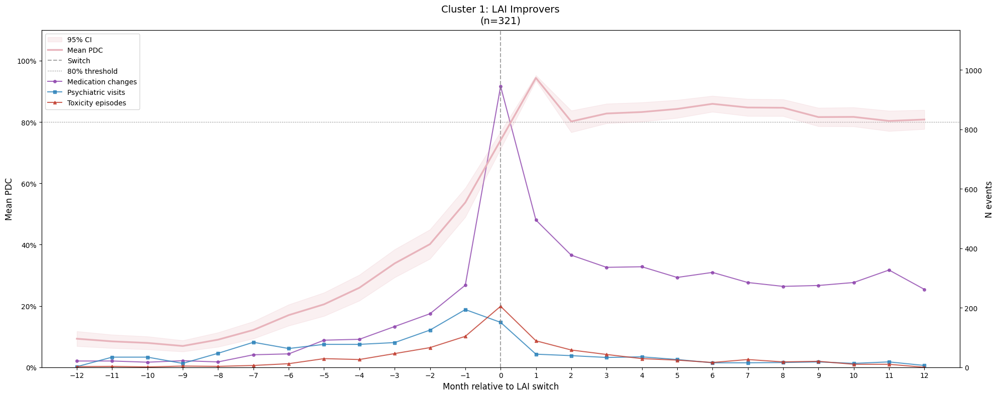

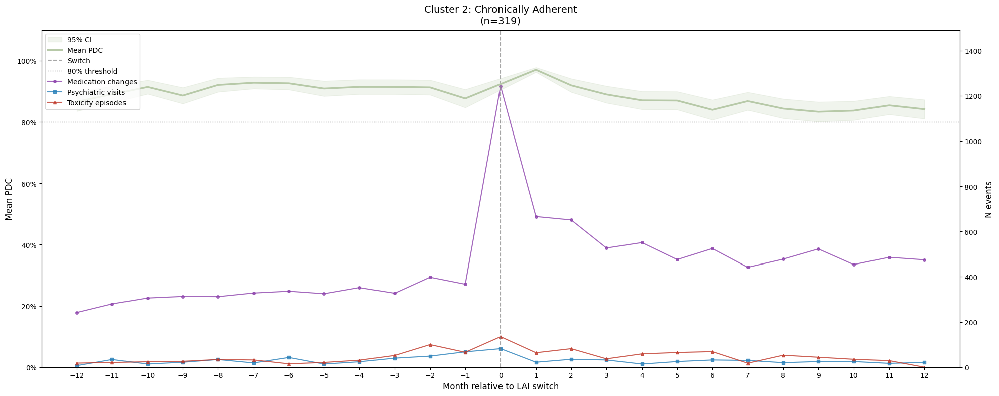

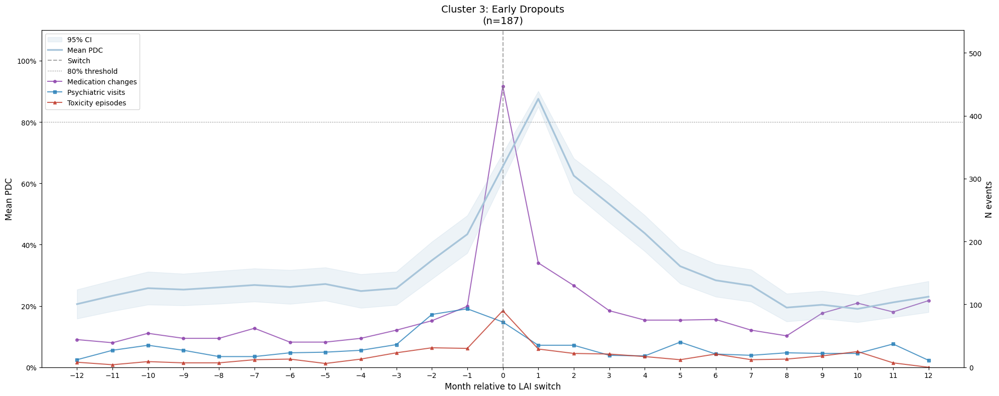

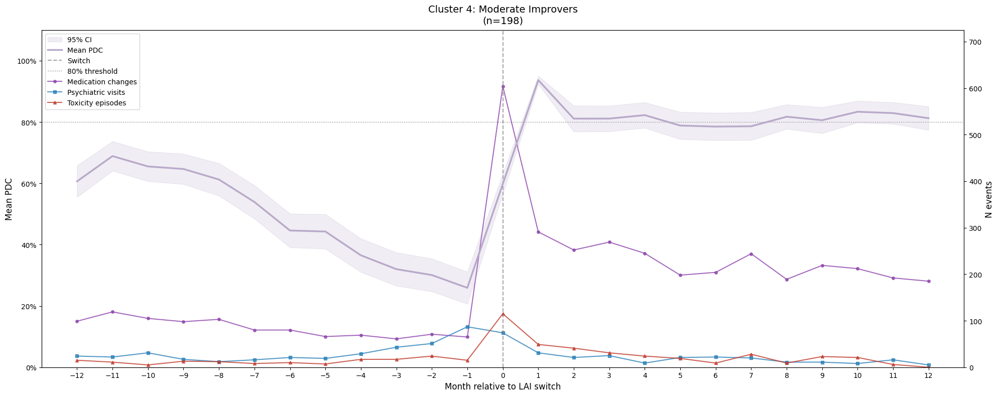

In [84]:
# Medication changes, visits urg sma smh generating toxicity all related
from scipy import stats
import numpy as np

event_colors = {
    'Medication changes': '#8E44AD',
    'Psychiatric visits': '#2980B9', 
    'Toxicity episodes': '#C0392B'
}

for cluster_id in range(4):
    fig, ax1 = plt.subplots(figsize=(20, 8))
    ax2 = ax1.twinx()
    
    # PDC line on ax1
    cluster_data = pdc_switchers_csv[pdc_switchers_csv['cluster_k4'] == cluster_id]
    mean_pdc = cluster_data[cols].mean().values
    sem_pdc = cluster_data[cols].sem().values
    ci95 = 1.96 * sem_pdc
    
    ax1.fill_between(months,
                     np.clip(mean_pdc - ci95, 0, 1),
                     np.clip(mean_pdc + ci95, 0, 1),
                     color=custom_k4[cluster_id], alpha=0.2, label='95% CI', zorder=3)
    ax1.plot(months, mean_pdc, color=custom_k4[cluster_id], linewidth=2.5,
             label='Mean PDC', zorder=4)
    ax1.axvline(x=0, color='grey', linestyle='--', alpha=0.7, label='Switch')
    ax1.axhline(y=0.80, color='black', linestyle=':', linewidth=1, alpha=0.5, label='80% threshold')
    ax1.set_ylim(0, 1.1)
    ax1.set_ylabel('Mean PDC', fontsize=12)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*100:.0f}%'))
    ax1.set_xticks(range(-12, 13))
    ax1.set_xlim(-13, 13)
    ax1.set_zorder(ax2.get_zorder() + 1)
    ax1.patch.set_visible(False)
    
    # Medication changes per month
    cluster_med = med_changes_all[med_changes_all['cluster_k4'] == cluster_id].copy()
    cluster_med['month'] = (cluster_med['days_to_switch'] / 30.44).round().astype(int)
    cluster_med = cluster_med[cluster_med['month'].between(-12, 12)]
    med_monthly = cluster_med.groupby('month').size().reindex(range(-12, 13), fill_value=0)
    
    # Psychiatric visits per month
    all_visits_cluster = pd.concat([
        df_urg_cohort[df_urg_cohort['cluster_k4'] == cluster_id][['visit_month']],
        df_smh_cohort[df_smh_cohort['cluster_k4'] == cluster_id][['visit_month']],
        df_sma_cohort[df_sma_cohort['cluster_k4'] == cluster_id][['visit_month']]
    ])
    visits_monthly = all_visits_cluster.groupby('visit_month').size().reindex(range(-12, 13), fill_value=0)
    
    # Toxicity episodes per month  
    cluster_tox = toxicity_events[
        (toxicity_events['cluster_k4'] == cluster_id)].copy()
    tox_monthly = cluster_tox.groupby('month_to_switch').size().reindex(range(-12, 13), fill_value=0)

    # Plot three lines on ax2
    ax2.plot(range(-12, 13), med_monthly.values, color=event_colors['Medication changes'],
             linewidth=1.5, marker='o', markersize=4, label='Medication changes', alpha=0.8)
    ax2.plot(range(-12, 13), visits_monthly.values, color=event_colors['Psychiatric visits'],
             linewidth=1.5, marker='s', markersize=4, label='Psychiatric visits', alpha=0.8)
    ax2.plot(range(-12, 13), tox_monthly.values, color=event_colors['Toxicity episodes'],
             linewidth=1.5, marker='^', markersize=4, label='Toxicity episodes', alpha=0.8)
    
    ax2.set_ylabel('N events', fontsize=12)
    ax2.set_ylim(0, max(med_monthly.max(), visits_monthly.max(), tox_monthly.max()) * 1.2)
    
    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(handles1 + handles2, labels1 + labels2, fontsize=10, loc='upper left')
    
    ax1.set_xlabel('Month relative to LAI switch', fontsize=12)
    ax1.set_title(f'Cluster {cluster_id + 1}: {cluster_labels[cluster_id]}\n(n={len(cluster_data)})',
                  fontsize=14, pad=10)
    
    plt.tight_layout()
    plt.show()